## EV Battery Range Predection is Machine Learning techinique used to predect the distance an electric vehicle can travel on it's available battery charge. It analyzes factors such as Battery Capacity , vehicle speed , weight , temperature and enegry consuption to estimate the vehicle's expected riving range in Kilometer. 

In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
!pip install datasets

In [117]:
import sys
print(sys.executable)

/Users/sanjayanand/jupyter-env/bin/python


In [118]:
import sys
!{sys.executable} -m pip install datasets


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: /Users/sanjayanand/jupyter-env/bin/python -m pip install --upgrade pip


In [119]:
from datasets import load_dataset

ds = load_dataset("SohamThakkar-07/india-ev-range-dataset")

In [120]:
ds

DatasetDict({
    train: Dataset({
        features: ['make', 'model', 'variant', 'battery_capacity_kWh', 'battery_capacity_kWh_new', 'motor_power_kW', 'vehicle_weight_kg', 'drag_coefficient_Cd', 'frontal_area_m2', 'rolling_resistance_Cr', 'motor_efficiency_pct', 'ARAI_certified_range_km', 'avg_driving_speed_kmh', 'ambient_temperature_C', 'ac_usage', 'terrain_type', 'traffic_condition', 'driving_style', 'passengers', 'battery_age_years', 'tyre_pressure_deviation_psi', 'city_road_type', 'energy_consumption_kWh_per_km', 'real_world_range_km', 'price_lakh_INR'],
        num_rows: 7291
    })
})

In [121]:
type(ds)

datasets.dataset_dict.DatasetDict

In [122]:
df = ds['train'].to_pandas() # It converts your Hugging Face Dataset into a Pandas DataFrame and stores it in the variable df.

In [123]:
df

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
0,Tata,Nexon EV,Long Range,35.3,40.5,105,1610,0.34,2.4,0.0122,...,0,2,0,1,4.3,-2,Delhi,0.2504,141.00,17.5
1,Tata,Nexon EV,Long Range,40.5,40.5,105,1610,0.34,2.4,0.0120,...,0,2,1,3,0.0,0,Delhi,0.1198,338.00,17.5
2,Tata,Nexon EV,Long Range,39.3,40.5,105,1610,0.34,2.4,0.0122,...,0,1,1,3,1.0,-2,Delhi,0.1254,313.40,17.5
3,Tata,Nexon EV,Long Range,39.0,40.5,105,1610,0.34,2.4,0.0120,...,0,0,1,1,1.2,0,Delhi,0.0883,441.75,17.5
4,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,3,2.1,0,Delhi,0.1960,193.40,17.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7286,Smart,#1 Pro+,Standard,54.2,62.0,200,1820,0.29,2.3,0.0110,...,2,0,2,1,4.2,0,Ghat_Road,0.7486,72.40,25.0
7287,Smart,#1 Pro+,Standard,59.6,62.0,200,1820,0.29,2.3,0.0110,...,2,1,0,2,1.3,0,Ghat_Road,0.8430,70.70,25.0
7288,Smart,#1 Pro+,Standard,58.3,62.0,200,1820,0.29,2.3,0.0116,...,2,2,2,4,2.0,-5,Ghat_Road,1.3250,44.00,25.0
7289,Smart,#1 Pro+,Standard,53.6,62.0,200,1820,0.29,2.3,0.0110,...,2,2,1,1,4.5,0,Ghat_Road,1.2182,44.00,25.0


In [124]:
type(df)

pandas.DataFrame

In [125]:
df.head()

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
0,Tata,Nexon EV,Long Range,35.3,40.5,105,1610,0.34,2.4,0.0122,...,0,2,0,1,4.3,-2,Delhi,0.2504,141.00,17.5
1,Tata,Nexon EV,Long Range,40.5,40.5,105,1610,0.34,2.4,0.0120,...,0,2,1,3,0.0,0,Delhi,0.1198,338.00,17.5
2,Tata,Nexon EV,Long Range,39.3,40.5,105,1610,0.34,2.4,0.0122,...,0,1,1,3,1.0,-2,Delhi,0.1254,313.40,17.5
3,Tata,Nexon EV,Long Range,39.0,40.5,105,1610,0.34,2.4,0.0120,...,0,0,1,1,1.2,0,Delhi,0.0883,441.75,17.5
4,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,3,2.1,0,Delhi,0.1960,193.40,17.5


In [126]:
df.head(10)

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
0,Tata,Nexon EV,Long Range,35.3,40.5,105,1610,0.34,2.4,0.0122,...,0,2,0,1,4.3,-2,Delhi,0.2504,141.00,17.5
1,Tata,Nexon EV,Long Range,40.5,40.5,105,1610,0.34,2.4,0.0120,...,0,2,1,3,0.0,0,Delhi,0.1198,338.00,17.5
2,Tata,Nexon EV,Long Range,39.3,40.5,105,1610,0.34,2.4,0.0122,...,0,1,1,3,1.0,-2,Delhi,0.1254,313.40,17.5
3,Tata,Nexon EV,Long Range,39.0,40.5,105,1610,0.34,2.4,0.0120,...,0,0,1,1,1.2,0,Delhi,0.0883,441.75,17.5
4,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,3,2.1,0,Delhi,0.1960,193.40,17.5
5,Tata,Nexon EV,Long Range,38.8,40.5,105,1610,0.34,2.4,0.0126,...,0,0,1,2,1.4,-5,Delhi,0.1384,280.40,17.5
6,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,1,2.1,0,Delhi,0.2658,142.60,17.5
7,Tata,Nexon EV,Long Range,38.4,40.5,105,1610,0.34,2.4,0.0120,...,0,0,2,3,1.7,0,Delhi,0.1164,329.80,17.5
8,Tata,Nexon EV,Long Range,34.5,40.5,105,1610,0.34,2.4,0.0126,...,0,2,1,2,4.9,-5,Delhi,0.1774,194.50,17.5
9,Tata,Nexon EV,Long Range,36.6,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,1,3.2,0,Delhi,0.1426,256.70,17.5


In [127]:
df.tail()

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
7286,Smart,#1 Pro+,Standard,54.2,62.0,200,1820,0.29,2.3,0.0110,...,2,0,2,1,4.2,0,Ghat_Road,0.7486,72.4,25.0
7287,Smart,#1 Pro+,Standard,59.6,62.0,200,1820,0.29,2.3,0.0110,...,2,1,0,2,1.3,0,Ghat_Road,0.8430,70.7,25.0
7288,Smart,#1 Pro+,Standard,58.3,62.0,200,1820,0.29,2.3,0.0116,...,2,2,2,4,2.0,-5,Ghat_Road,1.3250,44.0,25.0
7289,Smart,#1 Pro+,Standard,53.6,62.0,200,1820,0.29,2.3,0.0110,...,2,2,1,1,4.5,0,Ghat_Road,1.2182,44.0,25.0
7290,Smart,#1 Pro+,Standard,56.2,62.0,200,1820,0.29,2.3,0.0119,...,2,0,0,2,3.1,-8,Ghat_Road,0.5972,94.1,25.0


In [128]:
df.columns

Index(['make', 'model', 'variant', 'battery_capacity_kWh',
       'battery_capacity_kWh_new', 'motor_power_kW', 'vehicle_weight_kg',
       'drag_coefficient_Cd', 'frontal_area_m2', 'rolling_resistance_Cr',
       'motor_efficiency_pct', 'ARAI_certified_range_km',
       'avg_driving_speed_kmh', 'ambient_temperature_C', 'ac_usage',
       'terrain_type', 'traffic_condition', 'driving_style', 'passengers',
       'battery_age_years', 'tyre_pressure_deviation_psi', 'city_road_type',
       'energy_consumption_kWh_per_km', 'real_world_range_km',
       'price_lakh_INR'],
      dtype='str')

In [129]:
df.shape[0] # It show number is Rows 

7291

In [130]:
df.shape[1] # It shows number of Columns 

25

In [131]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7291 entries, 0 to 7290
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   make                           7291 non-null   str    
 1   model                          7291 non-null   str    
 2   variant                        7291 non-null   str    
 3   battery_capacity_kWh           7291 non-null   float64
 4   battery_capacity_kWh_new       7291 non-null   float64
 5   motor_power_kW                 7291 non-null   int64  
 6   vehicle_weight_kg              7291 non-null   int64  
 7   drag_coefficient_Cd            7291 non-null   float64
 8   frontal_area_m2                7291 non-null   float64
 9   rolling_resistance_Cr          7291 non-null   float64
 10  motor_efficiency_pct           7291 non-null   int64  
 11  ARAI_certified_range_km        7291 non-null   int64  
 12  avg_driving_speed_kmh          7291 non-null   float64
 13 

In [132]:
df.isnull().sum()

make                             0
model                            0
variant                          0
battery_capacity_kWh             0
battery_capacity_kWh_new         0
motor_power_kW                   0
vehicle_weight_kg                0
drag_coefficient_Cd              0
frontal_area_m2                  0
rolling_resistance_Cr            0
motor_efficiency_pct             0
ARAI_certified_range_km          0
avg_driving_speed_kmh            0
ambient_temperature_C            0
ac_usage                         0
terrain_type                     0
traffic_condition                0
driving_style                    0
passengers                       0
battery_age_years                0
tyre_pressure_deviation_psi      0
city_road_type                   0
energy_consumption_kWh_per_km    0
real_world_range_km              0
price_lakh_INR                   0
dtype: int64

In [133]:
df.describe()

,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,motor_efficiency_pct,ARAI_certified_range_km,avg_driving_speed_kmh,...,ac_usage,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
count,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,...,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000
mean,57.063503,61.730462,192.297764,1915.502263,0.291849,2.414042,0.011578,92.048553,482.534220,38.112317,...,0.302290,0.498148,1.123714,0.939652,2.364148,2.514031,-2.226718,0.361858,236.426800,62.213894
std,21.639038,23.235641,114.756511,459.599245,0.037737,0.176069,0.000964,1.532851,115.686303,26.438745,...,0.459282,0.765039,0.818042,0.658119,1.194649,1.431435,2.789512,0.303706,145.732568,100.673982
min,14.700000,17.300000,30.000000,840.000000,0.200000,1.800000,0.009000,88.000000,230.000000,12.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,-8.000000,0.068600,23.000000,7.000000
25%,39.800000,44.500000,110.000000,1620.000000,0.280000,2.330000,0.011000,91.000000,418.000000,21.500000,...,0.000000,0.000000,0.000000,1.000000,1.000000,1.300000,-5.000000,0.162000,111.900000,18.000000
50%,57.500000,61.000000,160.000000,1900.000000,0.290000,2.400000,0.011600,92.000000,476.000000,28.000000,...,0.000000,0.000000,1.000000,1.000000,2.000000,2.500000,-2.000000,0.246000,212.600000,29.000000
75%,71.500000,77.400000,250.000000,2170.000000,0.320000,2.480000,0.012200,93.000000,542.000000,37.600000,...,1.000000,1.000000,2.000000,1.000000,3.000000,3.700000,0.000000,0.450950,335.500000,65.000000
max,107.800000,107.800000,560.000000,2975.000000,0.350000,2.850000,0.014000,95.000000,857.000000,120.000000,...,1.000000,2.000000,2.000000,2.000000,5.000000,5.000000,2.000000,1.787200,814.150000,750.000000


In [134]:
df.duplicated().sum() # It will show where duplicated row is their 

np.int64(0)

In [135]:
df['make'].value_counts() # Count of the row [0]

make
Tata             1435
BYD               709
MG                609
Mahindra          601
BMW               590
Mercedes          486
Hyundai           482
Kia               361
Audi              356
Volvo             355
Citroen           251
Porsche           234
Maruti Suzuki     233
Smart             125
Jaguar            120
Mini              119
Rolls-Royce       114
Toyota            111
Name: count, dtype: int64

array([[<Axes: title={'center': 'battery_capacity_kWh'}>,
        <Axes: title={'center': 'battery_capacity_kWh_new'}>,
        <Axes: title={'center': 'motor_power_kW'}>,
        <Axes: title={'center': 'vehicle_weight_kg'}>,
        <Axes: title={'center': 'drag_coefficient_Cd'}>],
       [<Axes: title={'center': 'frontal_area_m2'}>,
        <Axes: title={'center': 'rolling_resistance_Cr'}>,
        <Axes: title={'center': 'motor_efficiency_pct'}>,
        <Axes: title={'center': 'ARAI_certified_range_km'}>,
        <Axes: title={'center': 'avg_driving_speed_kmh'}>],
       [<Axes: title={'center': 'ambient_temperature_C'}>,
        <Axes: title={'center': 'ac_usage'}>,
        <Axes: title={'center': 'terrain_type'}>,
        <Axes: title={'center': 'traffic_condition'}>,
        <Axes: title={'center': 'driving_style'}>],
       [<Axes: title={'center': 'passengers'}>,
        <Axes: title={'center': 'battery_age_years'}>,
        <Axes: title={'center': 'tyre_pressure_deviation_ps

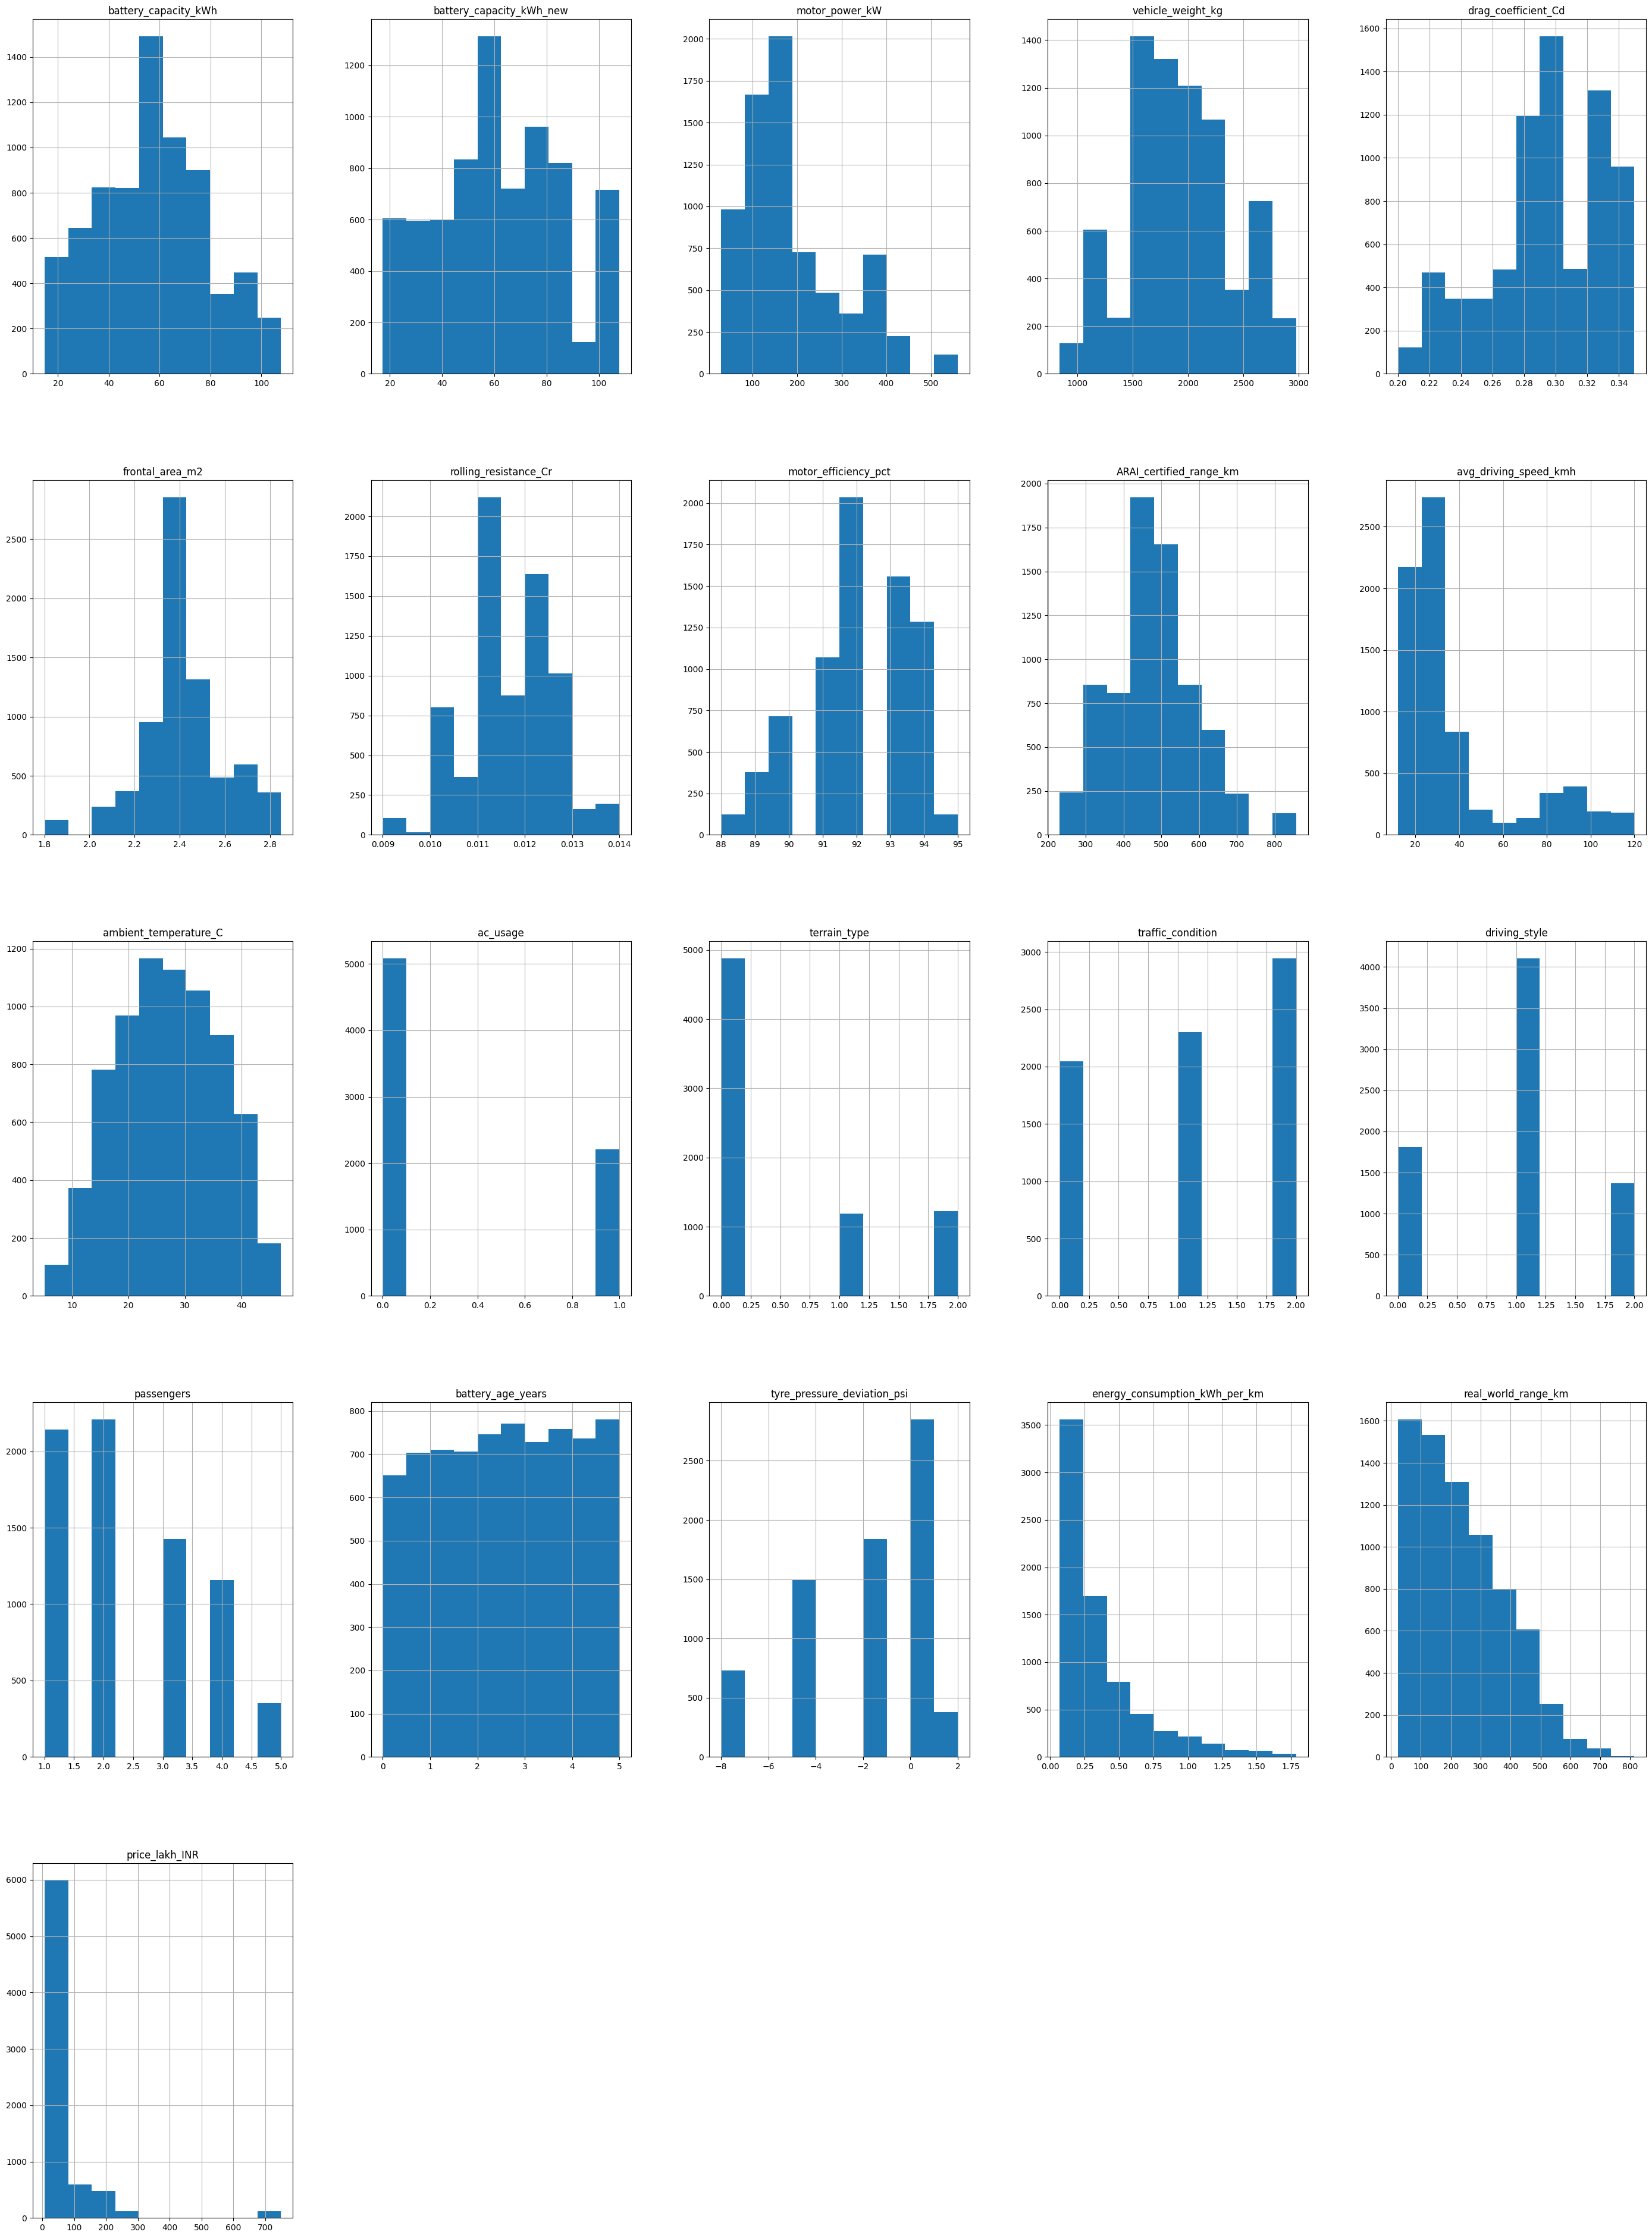

In [136]:
df.hist(figsize = (35,48))

In [137]:
df.corr(numeric_only = True)

,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,motor_efficiency_pct,ARAI_certified_range_km,avg_driving_speed_kmh,...,ac_usage,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
battery_capacity_kWh,1.000000,0.991410,0.850751,0.958838,-0.742529,0.713102,-0.654403,0.769892,0.796088,-0.005199,...,-0.007552,-0.000898,0.022251,0.011352,0.001436,-0.111217,-0.016659,0.274884,0.325388,0.569141
battery_capacity_kWh_new,0.991410,1.000000,0.859361,0.967151,-0.748877,0.718789,-0.660655,0.775703,0.802419,-0.005839,...,-0.007177,-0.000573,0.021822,0.010054,0.000514,0.011360,-0.018178,0.275526,0.321711,0.574633
motor_power_kW,0.850751,0.859361,1.000000,0.851273,-0.784212,0.511547,-0.704757,0.780829,0.613273,0.000293,...,-0.008782,-0.001305,0.017864,0.020397,-0.000518,0.016320,-0.018282,0.239165,0.260623,0.672241
vehicle_weight_kg,0.958838,0.967151,0.851273,1.000000,-0.670758,0.807215,-0.584069,0.712964,0.728941,-0.006978,...,-0.007226,0.000040,0.024037,0.008340,-0.002002,0.012584,-0.021398,0.277986,0.293342,0.631406
drag_coefficient_Cd,-0.742529,-0.748877,-0.784212,-0.670758,1.000000,-0.202291,0.874025,-0.891029,-0.667357,0.002116,...,0.013575,0.004015,-0.024207,-0.013679,0.003290,-0.002540,-0.003237,-0.192396,-0.272907,-0.465917
frontal_area_m2,0.713102,0.718789,0.511547,0.807215,-0.202291,1.000000,-0.151777,0.390483,0.528534,-0.011831,...,-0.005273,0.002128,0.019680,0.012854,0.002732,0.010850,-0.028381,0.213031,0.204293,0.455258
rolling_resistance_Cr,-0.654403,-0.660655,-0.704757,-0.584069,0.874025,-0.151777,1.000000,-0.843716,-0.612227,0.003949,...,0.010673,0.007098,-0.019674,-0.025947,0.005857,-0.005346,-0.302191,-0.158643,-0.252997,-0.454284
motor_efficiency_pct,0.769892,0.775703,0.780829,0.712964,-0.891029,0.390483,-0.843716,1.000000,0.759153,-0.007353,...,-0.018902,-0.003783,0.030434,0.025069,0.005176,-0.000042,-0.003328,0.192902,0.297668,0.457901
ARAI_certified_range_km,0.796088,0.802419,0.613273,0.728941,-0.667357,0.528534,-0.612227,0.759153,1.000000,-0.008166,...,-0.003621,-0.006710,0.026522,0.013293,0.008365,0.007431,-0.000792,0.151913,0.366001,0.313046
avg_driving_speed_kmh,-0.005199,-0.005839,0.000293,-0.006978,0.002116,-0.011831,0.003949,-0.007353,-0.008166,1.000000,...,0.051109,-0.268163,-0.398331,0.006849,0.010540,0.004873,-0.006887,-0.198825,0.145469,0.000550


In [138]:
df

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
0,Tata,Nexon EV,Long Range,35.3,40.5,105,1610,0.34,2.4,0.0122,...,0,2,0,1,4.3,-2,Delhi,0.2504,141.00,17.5
1,Tata,Nexon EV,Long Range,40.5,40.5,105,1610,0.34,2.4,0.0120,...,0,2,1,3,0.0,0,Delhi,0.1198,338.00,17.5
2,Tata,Nexon EV,Long Range,39.3,40.5,105,1610,0.34,2.4,0.0122,...,0,1,1,3,1.0,-2,Delhi,0.1254,313.40,17.5
3,Tata,Nexon EV,Long Range,39.0,40.5,105,1610,0.34,2.4,0.0120,...,0,0,1,1,1.2,0,Delhi,0.0883,441.75,17.5
4,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,3,2.1,0,Delhi,0.1960,193.40,17.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7286,Smart,#1 Pro+,Standard,54.2,62.0,200,1820,0.29,2.3,0.0110,...,2,0,2,1,4.2,0,Ghat_Road,0.7486,72.40,25.0
7287,Smart,#1 Pro+,Standard,59.6,62.0,200,1820,0.29,2.3,0.0110,...,2,1,0,2,1.3,0,Ghat_Road,0.8430,70.70,25.0
7288,Smart,#1 Pro+,Standard,58.3,62.0,200,1820,0.29,2.3,0.0116,...,2,2,2,4,2.0,-5,Ghat_Road,1.3250,44.00,25.0
7289,Smart,#1 Pro+,Standard,53.6,62.0,200,1820,0.29,2.3,0.0110,...,2,2,1,1,4.5,0,Ghat_Road,1.2182,44.00,25.0


In [139]:
df['energy_consumption_kWh_per_km'].skew()

np.float64(1.9155262714847232)

In [140]:
df['price_lakh_INR'].skew()

np.float64(5.139949803609063)

In [141]:
for column in df.select_dtypes(include = 'number' ).columns:
    skew = df[column].skew()

    if skew > 0.5:
        result = "Right Skew"
    elif skew < -0.5:
        result = "Left Skew"
    else:
        result = "Appromaxily Symentric"
    print(column , ':' , round(skew,2) , '-->' , result)
    print('\n')

battery_capacity_kWh : 0.11 --> Appromaxily Symentric


battery_capacity_kWh_new : 0.08 --> Appromaxily Symentric


motor_power_kW : 1.03 --> Right Skew


vehicle_weight_kg : 0.1 --> Appromaxily Symentric


drag_coefficient_Cd : -0.39 --> Appromaxily Symentric


frontal_area_m2 : -0.17 --> Appromaxily Symentric


rolling_resistance_Cr : 0.01 --> Appromaxily Symentric


motor_efficiency_pct : -0.47 --> Appromaxily Symentric


ARAI_certified_range_km : 0.39 --> Appromaxily Symentric


avg_driving_speed_kmh : 1.58 --> Right Skew


ambient_temperature_C : -0.05 --> Appromaxily Symentric


ac_usage : 0.86 --> Right Skew


terrain_type : 1.13 --> Right Skew


traffic_condition : -0.23 --> Appromaxily Symentric


driving_style : 0.06 --> Appromaxily Symentric


passengers : 0.51 --> Right Skew


battery_age_years : -0.02 --> Appromaxily Symentric


tyre_pressure_deviation_psi : -0.71 --> Left Skew


energy_consumption_kWh_per_km : 1.92 --> Right Skew


real_world_range_km : 0.65 --> Right Ske

array([[<Axes: title={'center': 'battery_capacity_kWh'}>,
        <Axes: title={'center': 'battery_capacity_kWh_new'}>,
        <Axes: title={'center': 'motor_power_kW'}>,
        <Axes: title={'center': 'vehicle_weight_kg'}>,
        <Axes: title={'center': 'drag_coefficient_Cd'}>],
       [<Axes: title={'center': 'frontal_area_m2'}>,
        <Axes: title={'center': 'rolling_resistance_Cr'}>,
        <Axes: title={'center': 'motor_efficiency_pct'}>,
        <Axes: title={'center': 'ARAI_certified_range_km'}>,
        <Axes: title={'center': 'avg_driving_speed_kmh'}>],
       [<Axes: title={'center': 'ambient_temperature_C'}>,
        <Axes: title={'center': 'ac_usage'}>,
        <Axes: title={'center': 'terrain_type'}>,
        <Axes: title={'center': 'traffic_condition'}>,
        <Axes: title={'center': 'driving_style'}>],
       [<Axes: title={'center': 'passengers'}>,
        <Axes: title={'center': 'battery_age_years'}>,
        <Axes: title={'center': 'tyre_pressure_deviation_ps

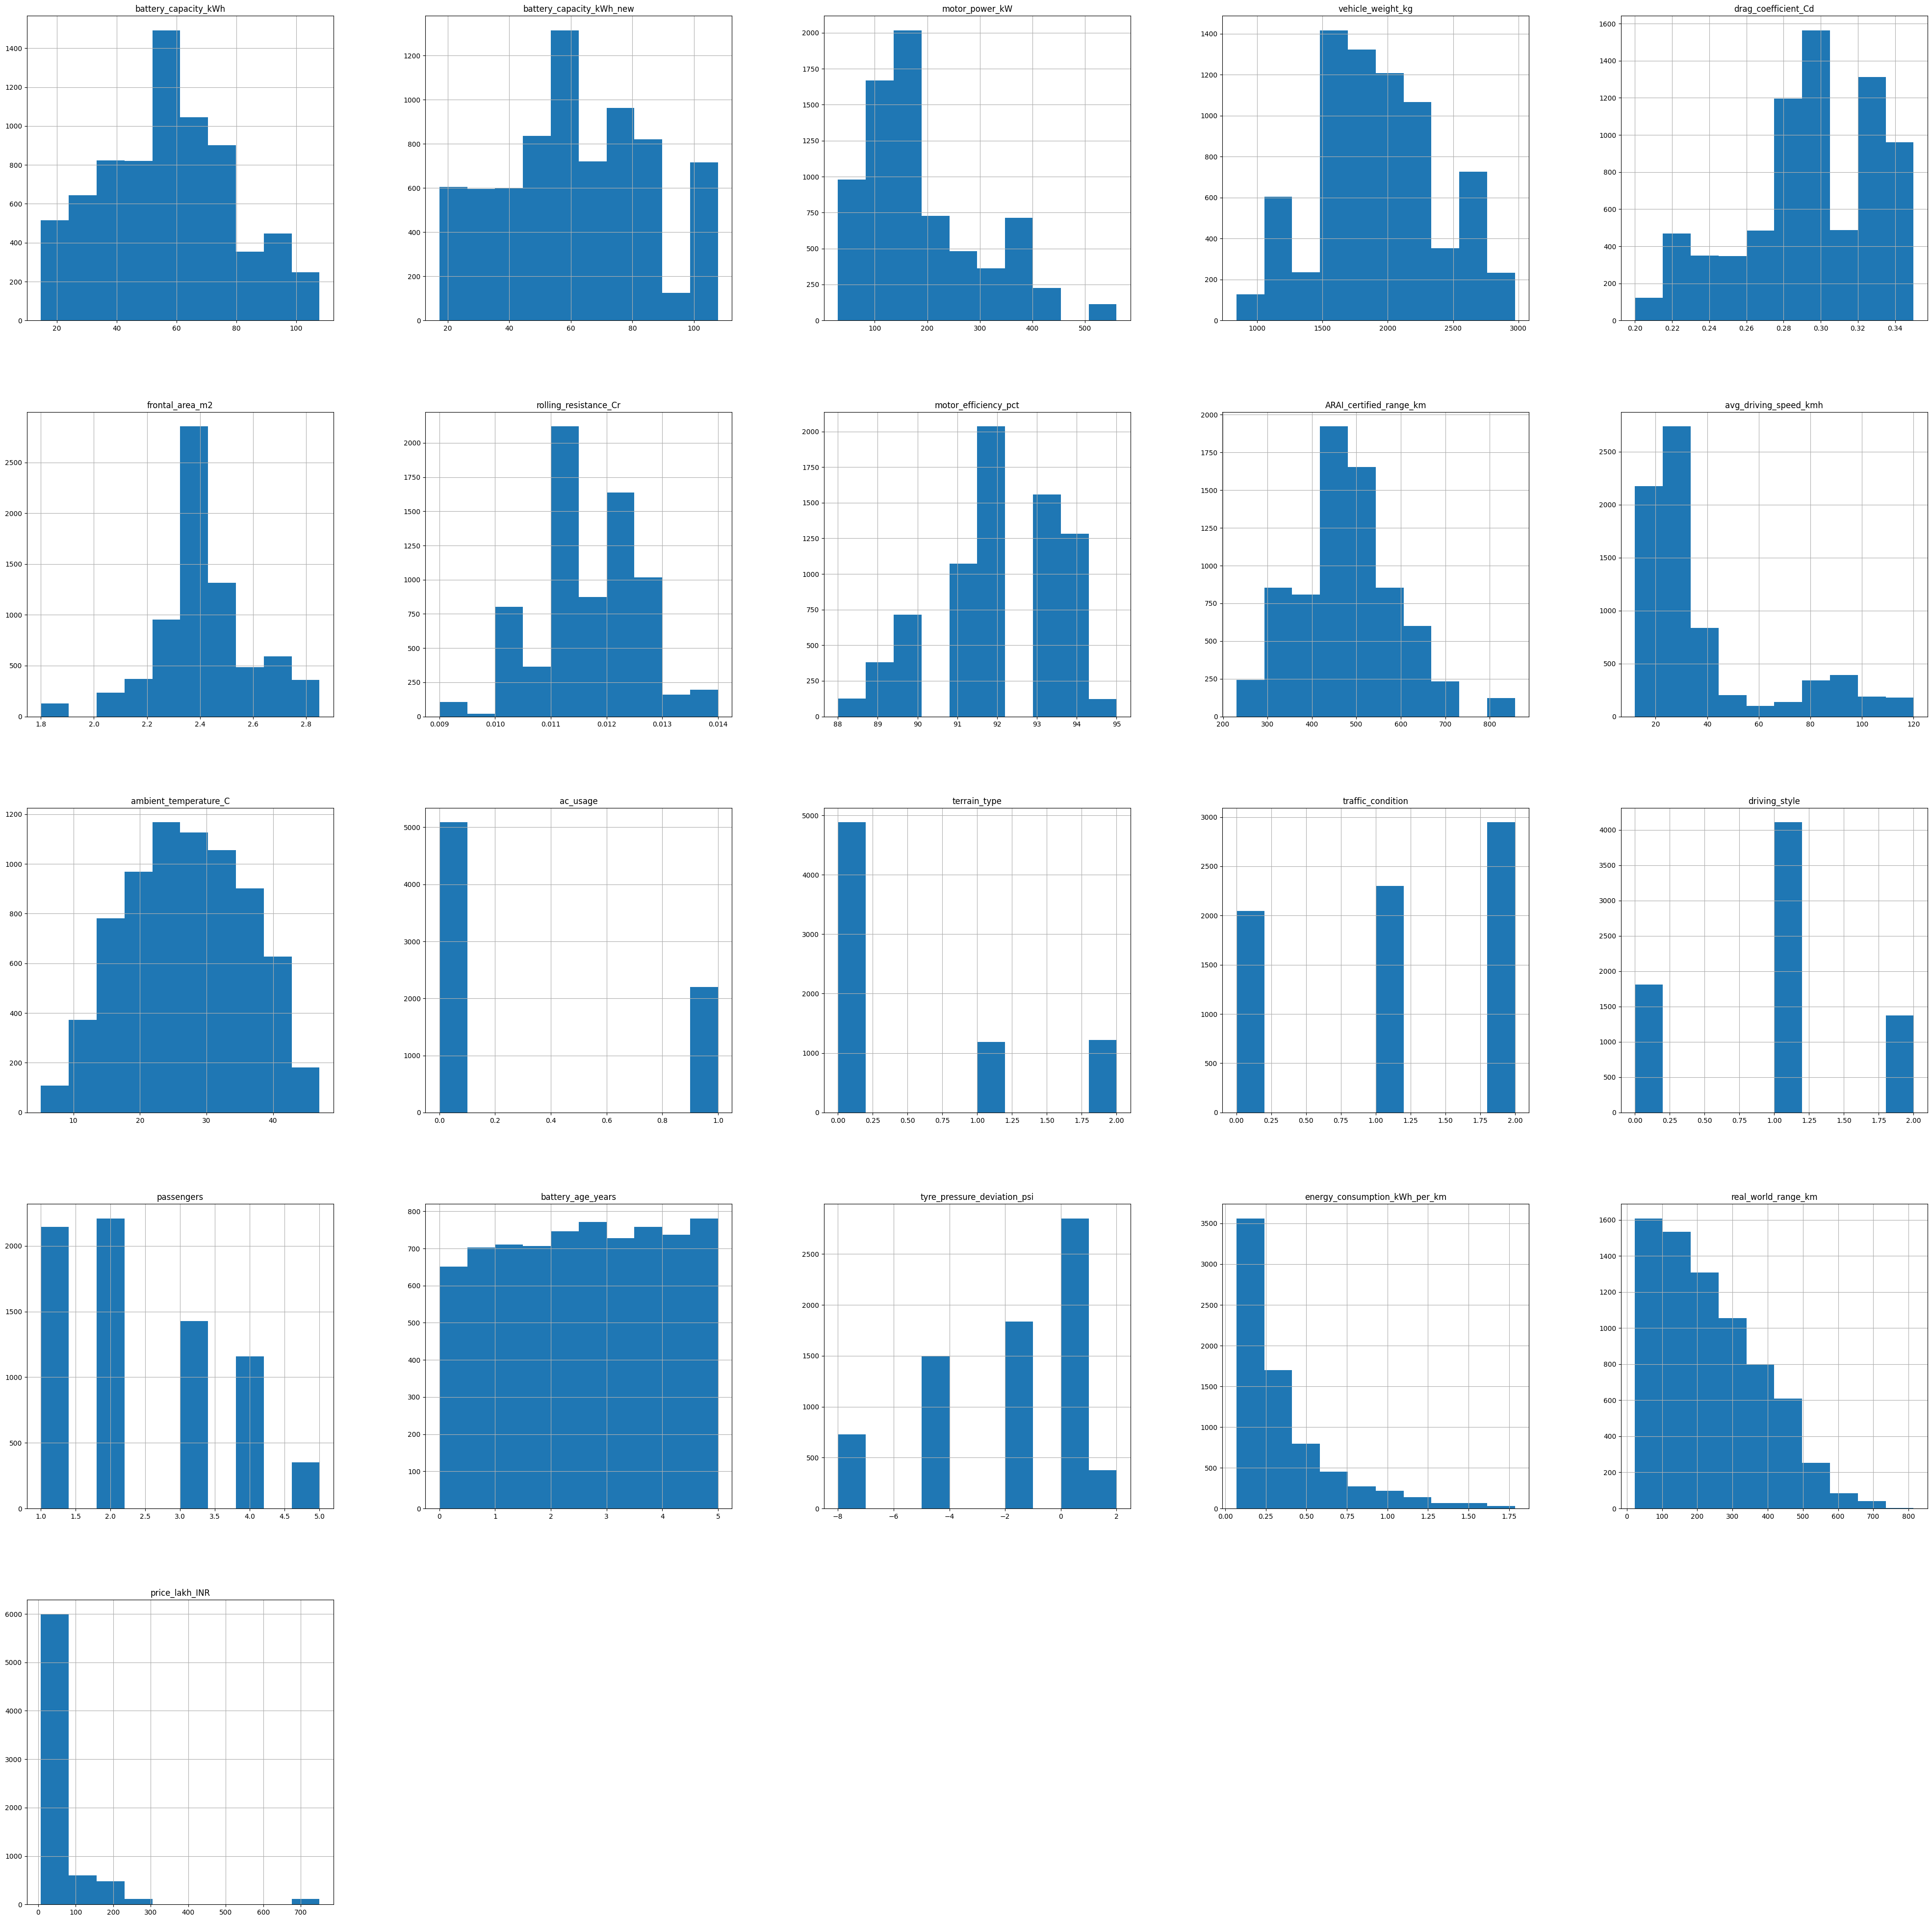

In [142]:
df.hist(figsize = (50,50))

In [143]:
df.select_dtypes(include = 'number' ).columns

Index(['battery_capacity_kWh', 'battery_capacity_kWh_new', 'motor_power_kW',
       'vehicle_weight_kg', 'drag_coefficient_Cd', 'frontal_area_m2',
       'rolling_resistance_Cr', 'motor_efficiency_pct',
       'ARAI_certified_range_km', 'avg_driving_speed_kmh',
       'ambient_temperature_C', 'ac_usage', 'terrain_type',
       'traffic_condition', 'driving_style', 'passengers', 'battery_age_years',
       'tyre_pressure_deviation_psi', 'energy_consumption_kWh_per_km',
       'real_world_range_km', 'price_lakh_INR'],
      dtype='str')

In [144]:
df.select_dtypes(include = 'object').columns

/var/folders/gl/vst17zv56p51b_8_y3rw_20c0000gn/T/ipykernel_11803/2393681377.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include = 'object').columns


Index(['make', 'model', 'variant', 'city_road_type'], dtype='str')

In [145]:
for col in ['ac_usage', 'terrain_type', 'traffic_condition', 'driving_style']:
    print(col, ":", df[col].unique())

ac_usage : [1 0]
terrain_type : [0 1 2]
traffic_condition : [2 1 0]
driving_style : [0 1 2]


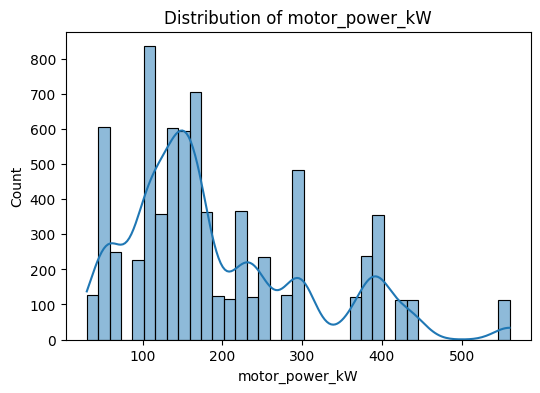

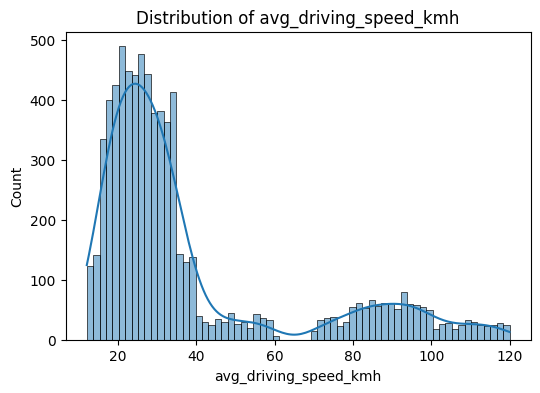

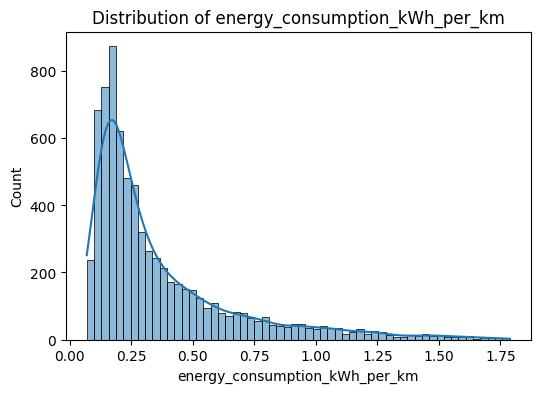

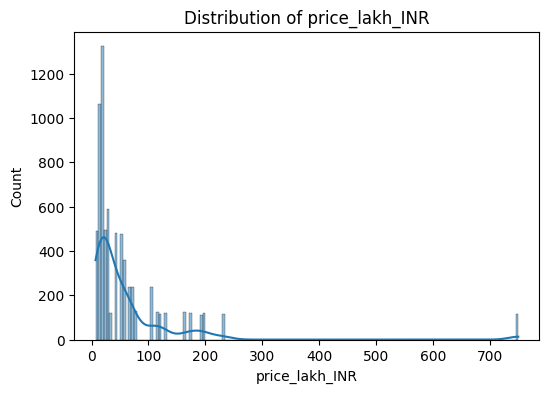

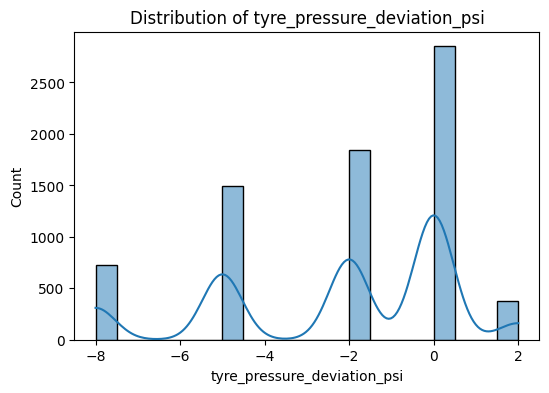

In [146]:
skewed_cols = [
    "motor_power_kW",
    "avg_driving_speed_kmh",
    "energy_consumption_kWh_per_km",
    "price_lakh_INR",
    "tyre_pressure_deviation_psi"
]

for col in skewed_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

In [147]:
unique_col = df.select_dtypes(include = 'str').columns

In [148]:
for col in unique_col :
    print(col , ':' , df[col].unique())
    print('\n')

make : <ArrowStringArray>
[         'Tata',      'Mahindra',            'MG',       'Hyundai',
           'Kia',           'BYD',           'BMW',      'Mercedes',
          'Audi',         'Volvo',       'Porsche',        'Jaguar',
       'Citroen', 'Maruti Suzuki',        'Toyota',   'Rolls-Royce',
          'Mini',         'Smart']
Length: 18, dtype: str


model : <ArrowStringArray>
[        'Nexon EV',         'Tiago EV',         'Tigor EV',
         'Punch EV',         'Curvv EV',       'Harrier EV',
        'Sierra EV',           'XUV400',           'XEV 9e',
             'BE 6',           'XUV.e8',            'ZS EV',
         'Comet EV',       'Windsor EV',         'Cloud EV',
          'Ioniq 5',         'Creta EV',              'EV6',
              'EV9',           'Atto 3',             'Seal',
               'e6',           'eMAX 7',              'iX1',
               'iX',               'i4',               'i5',
               'i7',              'EQS',          'EQS SUV',
 

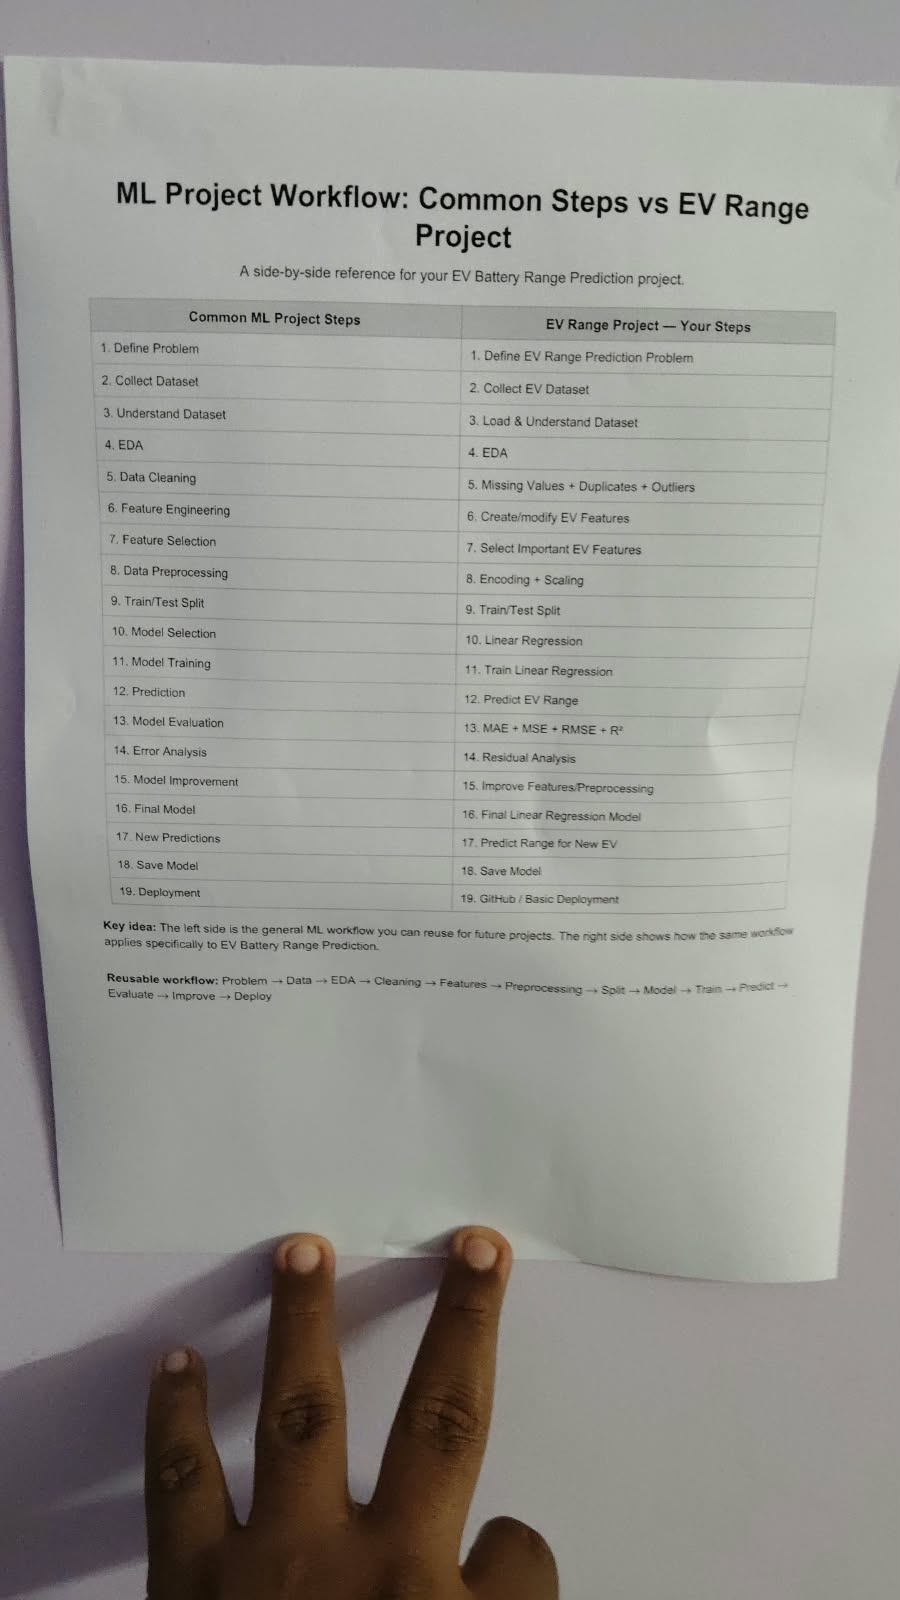

# Data Cleaning 

Missing Values + Duplicates  + Outliers 

In [149]:
df.isnull().sum()

make                             0
model                            0
variant                          0
battery_capacity_kWh             0
battery_capacity_kWh_new         0
motor_power_kW                   0
vehicle_weight_kg                0
drag_coefficient_Cd              0
frontal_area_m2                  0
rolling_resistance_Cr            0
motor_efficiency_pct             0
ARAI_certified_range_km          0
avg_driving_speed_kmh            0
ambient_temperature_C            0
ac_usage                         0
terrain_type                     0
traffic_condition                0
driving_style                    0
passengers                       0
battery_age_years                0
tyre_pressure_deviation_psi      0
city_road_type                   0
energy_consumption_kWh_per_km    0
real_world_range_km              0
price_lakh_INR                   0
dtype: int64

In [150]:
df.duplicated().sum()

np.int64(0)

In [151]:
df

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
0,Tata,Nexon EV,Long Range,35.3,40.5,105,1610,0.34,2.4,0.0122,...,0,2,0,1,4.3,-2,Delhi,0.2504,141.00,17.5
1,Tata,Nexon EV,Long Range,40.5,40.5,105,1610,0.34,2.4,0.0120,...,0,2,1,3,0.0,0,Delhi,0.1198,338.00,17.5
2,Tata,Nexon EV,Long Range,39.3,40.5,105,1610,0.34,2.4,0.0122,...,0,1,1,3,1.0,-2,Delhi,0.1254,313.40,17.5
3,Tata,Nexon EV,Long Range,39.0,40.5,105,1610,0.34,2.4,0.0120,...,0,0,1,1,1.2,0,Delhi,0.0883,441.75,17.5
4,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,3,2.1,0,Delhi,0.1960,193.40,17.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7286,Smart,#1 Pro+,Standard,54.2,62.0,200,1820,0.29,2.3,0.0110,...,2,0,2,1,4.2,0,Ghat_Road,0.7486,72.40,25.0
7287,Smart,#1 Pro+,Standard,59.6,62.0,200,1820,0.29,2.3,0.0110,...,2,1,0,2,1.3,0,Ghat_Road,0.8430,70.70,25.0
7288,Smart,#1 Pro+,Standard,58.3,62.0,200,1820,0.29,2.3,0.0116,...,2,2,2,4,2.0,-5,Ghat_Road,1.3250,44.00,25.0
7289,Smart,#1 Pro+,Standard,53.6,62.0,200,1820,0.29,2.3,0.0110,...,2,2,1,1,4.5,0,Ghat_Road,1.2182,44.00,25.0


In [152]:
df['make'].duplicated(keep = False)

0       True
1       True
2       True
3       True
4       True
        ... 
7286    True
7287    True
7288    True
7289    True
7290    True
Name: make, Length: 7291, dtype: bool

In [153]:

for col in df.columns:
    duplicates = df[col].value_counts()
    duplicates = duplicates[duplicates > 1]

    if not duplicates.empty:
        print(f"\nColumn: {col}")
        print(duplicates)



Column: make
make
Tata             1435
BYD               709
MG                609
Mahindra          601
BMW               590
Mercedes          486
Hyundai           482
Kia               361
Audi              356
Volvo             355
Citroen           251
Porsche           234
Maruti Suzuki     233
Smart             125
Jaguar            120
Mini              119
Rolls-Royce       114
Toyota            111
Name: count, dtype: int64

Column: model
model
Nexon EV            362
Curvv EV            251
eC3                 251
Ioniq 5             247
XUV400              239
Tiago EV            236
ZS EV               236
XC40 Recharge       236
Punch EV            235
Creta EV            235
Seal                235
EV6                 234
Taycan              234
e Vitara            233
Atto 3              232
Cloud EV            129
EQA                 129
Comet EV            128
EV9                 127
e6                  125
#1 Pro+             125
Q8 e-tron           124
EQS       

In [154]:
df.describe()

,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,motor_efficiency_pct,ARAI_certified_range_km,avg_driving_speed_kmh,...,ac_usage,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
count,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,...,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000,7291.000000
mean,57.063503,61.730462,192.297764,1915.502263,0.291849,2.414042,0.011578,92.048553,482.534220,38.112317,...,0.302290,0.498148,1.123714,0.939652,2.364148,2.514031,-2.226718,0.361858,236.426800,62.213894
std,21.639038,23.235641,114.756511,459.599245,0.037737,0.176069,0.000964,1.532851,115.686303,26.438745,...,0.459282,0.765039,0.818042,0.658119,1.194649,1.431435,2.789512,0.303706,145.732568,100.673982
min,14.700000,17.300000,30.000000,840.000000,0.200000,1.800000,0.009000,88.000000,230.000000,12.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,-8.000000,0.068600,23.000000,7.000000
25%,39.800000,44.500000,110.000000,1620.000000,0.280000,2.330000,0.011000,91.000000,418.000000,21.500000,...,0.000000,0.000000,0.000000,1.000000,1.000000,1.300000,-5.000000,0.162000,111.900000,18.000000
50%,57.500000,61.000000,160.000000,1900.000000,0.290000,2.400000,0.011600,92.000000,476.000000,28.000000,...,0.000000,0.000000,1.000000,1.000000,2.000000,2.500000,-2.000000,0.246000,212.600000,29.000000
75%,71.500000,77.400000,250.000000,2170.000000,0.320000,2.480000,0.012200,93.000000,542.000000,37.600000,...,1.000000,1.000000,2.000000,1.000000,3.000000,3.700000,0.000000,0.450950,335.500000,65.000000
max,107.800000,107.800000,560.000000,2975.000000,0.350000,2.850000,0.014000,95.000000,857.000000,120.000000,...,1.000000,2.000000,2.000000,2.000000,5.000000,5.000000,2.000000,1.787200,814.150000,750.000000


In [155]:
for col in df.select_dtypes(include = 'number').columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    IQR = q3 - q1

    lower_limit = q1 - 1.5*IQR
    upper_limit = q3 + 1.5*IQR


    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    non_outliers = df[(df[col] > lower_limit) & (df[col] < upper_limit)]
    

outliers 

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
4668,BMW,i7,xDrive60,95.6,101.7,400,2720,0.25,2.7,0.0108,...,0,2,0,4,2.0,-8,Delhi,0.2369,403.50,196.0
4669,BMW,i7,xDrive60,101.1,101.7,400,2720,0.25,2.7,0.0100,...,0,2,0,4,0.2,0,Delhi,0.2370,426.50,196.0
4670,BMW,i7,xDrive60,99.6,101.7,400,2720,0.25,2.7,0.0100,...,0,2,1,1,0.7,0,Delhi,0.3701,269.10,196.0
4671,BMW,i7,xDrive60,91.3,101.7,400,2720,0.25,2.7,0.0100,...,0,2,1,2,3.4,0,Delhi,0.2348,388.80,196.0
4672,BMW,i7,xDrive60,97.1,101.7,400,2720,0.25,2.7,0.0105,...,0,1,1,2,1.5,-5,Delhi,0.1635,593.75,196.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7042,Rolls-Royce,Spectre,Standard,95.0,102.0,430,2975,0.25,2.8,0.0100,...,2,1,1,1,2.3,0,Ghat_Road,0.9378,101.30,750.0
7043,Rolls-Royce,Spectre,Standard,101.4,102.0,430,2975,0.25,2.8,0.0105,...,2,2,1,1,0.2,-5,Ghat_Road,1.4890,68.10,750.0
7044,Rolls-Royce,Spectre,Standard,101.4,102.0,430,2975,0.25,2.8,0.0102,...,2,0,2,1,0.2,-2,Ghat_Road,0.7556,134.20,750.0
7045,Rolls-Royce,Spectre,Standard,88.8,102.0,430,2975,0.25,2.8,0.0102,...,2,0,1,2,4.3,2,Ghat_Road,0.7064,125.70,750.0


In [156]:
non_outliers 

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
0,Tata,Nexon EV,Long Range,35.3,40.5,105,1610,0.34,2.4,0.0122,...,0,2,0,1,4.3,-2,Delhi,0.2504,141.00,17.5
1,Tata,Nexon EV,Long Range,40.5,40.5,105,1610,0.34,2.4,0.0120,...,0,2,1,3,0.0,0,Delhi,0.1198,338.00,17.5
2,Tata,Nexon EV,Long Range,39.3,40.5,105,1610,0.34,2.4,0.0122,...,0,1,1,3,1.0,-2,Delhi,0.1254,313.40,17.5
3,Tata,Nexon EV,Long Range,39.0,40.5,105,1610,0.34,2.4,0.0120,...,0,0,1,1,1.2,0,Delhi,0.0883,441.75,17.5
4,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,3,2.1,0,Delhi,0.1960,193.40,17.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7286,Smart,#1 Pro+,Standard,54.2,62.0,200,1820,0.29,2.3,0.0110,...,2,0,2,1,4.2,0,Ghat_Road,0.7486,72.40,25.0
7287,Smart,#1 Pro+,Standard,59.6,62.0,200,1820,0.29,2.3,0.0110,...,2,1,0,2,1.3,0,Ghat_Road,0.8430,70.70,25.0
7288,Smart,#1 Pro+,Standard,58.3,62.0,200,1820,0.29,2.3,0.0116,...,2,2,2,4,2.0,-5,Ghat_Road,1.3250,44.00,25.0
7289,Smart,#1 Pro+,Standard,53.6,62.0,200,1820,0.29,2.3,0.0110,...,2,2,1,1,4.5,0,Ghat_Road,1.2182,44.00,25.0


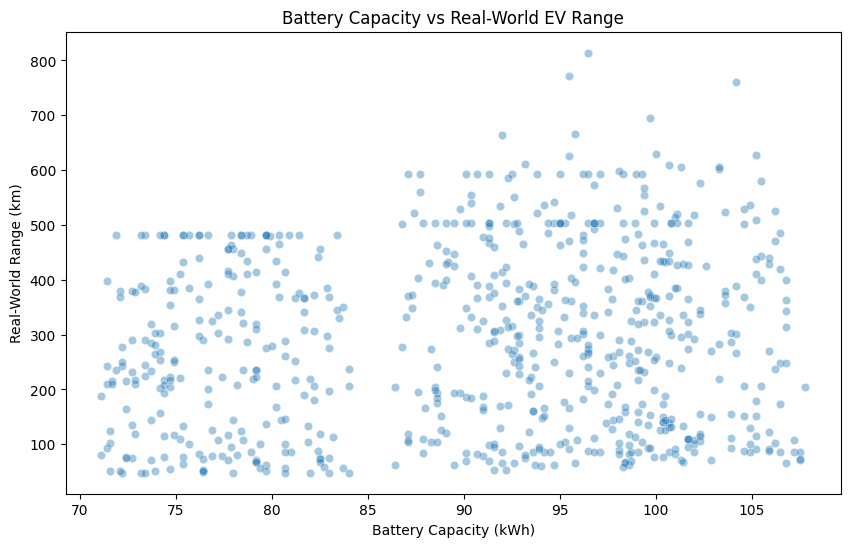

In [157]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x="battery_capacity_kWh",
    y="real_world_range_km",
    data=outliers,
    alpha=0.4
)

plt.title("Battery Capacity vs Real-World EV Range")
plt.xlabel("Battery Capacity (kWh)")
plt.ylabel("Real-World Range (km)")
plt.show()


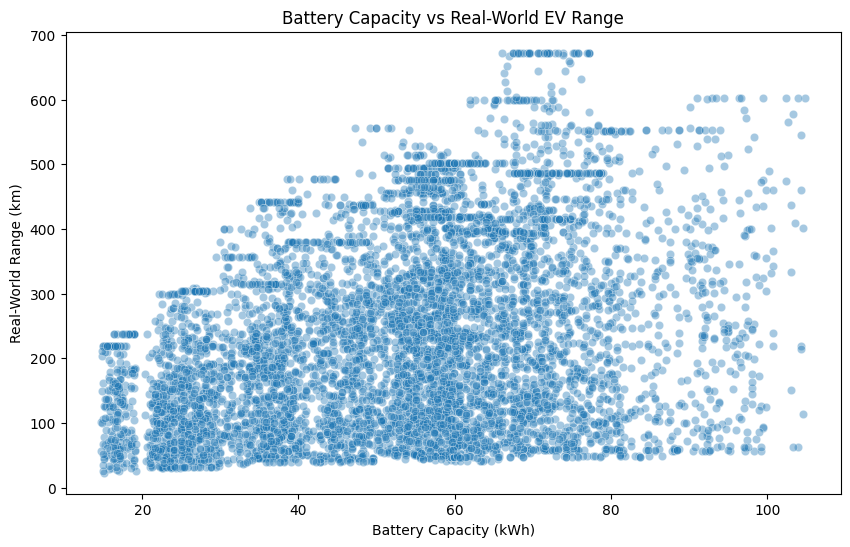

In [158]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x="battery_capacity_kWh",
    y="real_world_range_km",
    data=non_outliers,
    alpha=0.4
)

plt.title("Battery Capacity vs Real-World EV Range")
plt.xlabel("Battery Capacity (kWh)")
plt.ylabel("Real-World Range (km)")
plt.show()


In [159]:
df_clean = df.copy()

In [160]:
df.isnull().sum()

make                             0
model                            0
variant                          0
battery_capacity_kWh             0
battery_capacity_kWh_new         0
motor_power_kW                   0
vehicle_weight_kg                0
drag_coefficient_Cd              0
frontal_area_m2                  0
rolling_resistance_Cr            0
motor_efficiency_pct             0
ARAI_certified_range_km          0
avg_driving_speed_kmh            0
ambient_temperature_C            0
ac_usage                         0
terrain_type                     0
traffic_condition                0
driving_style                    0
passengers                       0
battery_age_years                0
tyre_pressure_deviation_psi      0
city_road_type                   0
energy_consumption_kWh_per_km    0
real_world_range_km              0
price_lakh_INR                   0
dtype: int64

In [161]:
df.duplicated().sum()

np.int64(0)

In [162]:
df

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
0,Tata,Nexon EV,Long Range,35.3,40.5,105,1610,0.34,2.4,0.0122,...,0,2,0,1,4.3,-2,Delhi,0.2504,141.00,17.5
1,Tata,Nexon EV,Long Range,40.5,40.5,105,1610,0.34,2.4,0.0120,...,0,2,1,3,0.0,0,Delhi,0.1198,338.00,17.5
2,Tata,Nexon EV,Long Range,39.3,40.5,105,1610,0.34,2.4,0.0122,...,0,1,1,3,1.0,-2,Delhi,0.1254,313.40,17.5
3,Tata,Nexon EV,Long Range,39.0,40.5,105,1610,0.34,2.4,0.0120,...,0,0,1,1,1.2,0,Delhi,0.0883,441.75,17.5
4,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,3,2.1,0,Delhi,0.1960,193.40,17.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7286,Smart,#1 Pro+,Standard,54.2,62.0,200,1820,0.29,2.3,0.0110,...,2,0,2,1,4.2,0,Ghat_Road,0.7486,72.40,25.0
7287,Smart,#1 Pro+,Standard,59.6,62.0,200,1820,0.29,2.3,0.0110,...,2,1,0,2,1.3,0,Ghat_Road,0.8430,70.70,25.0
7288,Smart,#1 Pro+,Standard,58.3,62.0,200,1820,0.29,2.3,0.0116,...,2,2,2,4,2.0,-5,Ghat_Road,1.3250,44.00,25.0
7289,Smart,#1 Pro+,Standard,53.6,62.0,200,1820,0.29,2.3,0.0110,...,2,2,1,1,4.5,0,Ghat_Road,1.2182,44.00,25.0


## Feature ENgineering 

In [163]:
df

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
0,Tata,Nexon EV,Long Range,35.3,40.5,105,1610,0.34,2.4,0.0122,...,0,2,0,1,4.3,-2,Delhi,0.2504,141.00,17.5
1,Tata,Nexon EV,Long Range,40.5,40.5,105,1610,0.34,2.4,0.0120,...,0,2,1,3,0.0,0,Delhi,0.1198,338.00,17.5
2,Tata,Nexon EV,Long Range,39.3,40.5,105,1610,0.34,2.4,0.0122,...,0,1,1,3,1.0,-2,Delhi,0.1254,313.40,17.5
3,Tata,Nexon EV,Long Range,39.0,40.5,105,1610,0.34,2.4,0.0120,...,0,0,1,1,1.2,0,Delhi,0.0883,441.75,17.5
4,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,3,2.1,0,Delhi,0.1960,193.40,17.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7286,Smart,#1 Pro+,Standard,54.2,62.0,200,1820,0.29,2.3,0.0110,...,2,0,2,1,4.2,0,Ghat_Road,0.7486,72.40,25.0
7287,Smart,#1 Pro+,Standard,59.6,62.0,200,1820,0.29,2.3,0.0110,...,2,1,0,2,1.3,0,Ghat_Road,0.8430,70.70,25.0
7288,Smart,#1 Pro+,Standard,58.3,62.0,200,1820,0.29,2.3,0.0116,...,2,2,2,4,2.0,-5,Ghat_Road,1.3250,44.00,25.0
7289,Smart,#1 Pro+,Standard,53.6,62.0,200,1820,0.29,2.3,0.0110,...,2,2,1,1,4.5,0,Ghat_Road,1.2182,44.00,25.0


In [164]:
df['battery_capacity_loose'] = (df['battery_capacity_kWh_new'] - df['battery_capacity_kWh'])

In [165]:
df['estimated_range_km'] = (df['battery_capacity_kWh'] / df['energy_consumption_kWh_per_km'])

In [166]:
df_encoded = pd.get_dummies(
    df,
    columns=["make", "model", "variant", "city_road_type"],
    dtype=int
)

In [167]:
df.head()

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR,battery_capacity_loose,estimated_range_km
0,Tata,Nexon EV,Long Range,35.3,40.5,105,1610,0.34,2.4,0.0122,...,0,1,4.3,-2,Delhi,0.2504,141.00,17.5,5.2,140.974441
1,Tata,Nexon EV,Long Range,40.5,40.5,105,1610,0.34,2.4,0.0120,...,1,3,0.0,0,Delhi,0.1198,338.00,17.5,0.0,338.063439
2,Tata,Nexon EV,Long Range,39.3,40.5,105,1610,0.34,2.4,0.0122,...,1,3,1.0,-2,Delhi,0.1254,313.40,17.5,1.2,313.397129
3,Tata,Nexon EV,Long Range,39.0,40.5,105,1610,0.34,2.4,0.0120,...,1,1,1.2,0,Delhi,0.0883,441.75,17.5,1.5,441.676104
4,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,3,2.1,0,Delhi,0.1960,193.40,17.5,2.6,193.367347


In [168]:
df_encoded

,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,motor_efficiency_pct,ARAI_certified_range_km,avg_driving_speed_kmh,...,city_road_type_Delhi,city_road_type_Expressway,city_road_type_Ghat_Road,city_road_type_Highway_NH,city_road_type_Hill_Station,city_road_type_Hyderabad,city_road_type_Kolkata,city_road_type_Mumbai,city_road_type_Pune,city_road_type_Rural_Road
0,35.3,40.5,105,1610,0.34,2.4,0.0122,91,465,27.0,...,1,0,0,0,0,0,0,0,0,0
1,40.5,40.5,105,1610,0.34,2.4,0.0120,91,465,15.0,...,1,0,0,0,0,0,0,0,0,0
2,39.3,40.5,105,1610,0.34,2.4,0.0122,91,465,20.8,...,1,0,0,0,0,0,0,0,0,0
3,39.0,40.5,105,1610,0.34,2.4,0.0120,91,465,33.8,...,1,0,0,0,0,0,0,0,0,0
4,37.9,40.5,105,1610,0.34,2.4,0.0120,91,465,18.5,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7286,54.2,62.0,200,1820,0.29,2.3,0.0110,92,440,31.4,...,0,0,1,0,0,0,0,0,0,0
7287,59.6,62.0,200,1820,0.29,2.3,0.0110,92,440,21.0,...,0,0,1,0,0,0,0,0,0,0
7288,58.3,62.0,200,1820,0.29,2.3,0.0116,92,440,26.0,...,0,0,1,0,0,0,0,0,0,0
7289,53.6,62.0,200,1820,0.29,2.3,0.0110,92,440,26.7,...,0,0,1,0,0,0,0,0,0,0


In [175]:
x  = df_encoded.drop('real_world_range_km',axis = 1)
y =  df_encoded['real_world_range_km']


In [176]:
x

,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,motor_efficiency_pct,ARAI_certified_range_km,avg_driving_speed_kmh,...,city_road_type_Delhi,city_road_type_Expressway,city_road_type_Ghat_Road,city_road_type_Highway_NH,city_road_type_Hill_Station,city_road_type_Hyderabad,city_road_type_Kolkata,city_road_type_Mumbai,city_road_type_Pune,city_road_type_Rural_Road
0,35.3,40.5,105,1610,0.34,2.4,0.0122,91,465,27.0,...,1,0,0,0,0,0,0,0,0,0
1,40.5,40.5,105,1610,0.34,2.4,0.0120,91,465,15.0,...,1,0,0,0,0,0,0,0,0,0
2,39.3,40.5,105,1610,0.34,2.4,0.0122,91,465,20.8,...,1,0,0,0,0,0,0,0,0,0
3,39.0,40.5,105,1610,0.34,2.4,0.0120,91,465,33.8,...,1,0,0,0,0,0,0,0,0,0
4,37.9,40.5,105,1610,0.34,2.4,0.0120,91,465,18.5,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7286,54.2,62.0,200,1820,0.29,2.3,0.0110,92,440,31.4,...,0,0,1,0,0,0,0,0,0,0
7287,59.6,62.0,200,1820,0.29,2.3,0.0110,92,440,21.0,...,0,0,1,0,0,0,0,0,0,0
7288,58.3,62.0,200,1820,0.29,2.3,0.0116,92,440,26.0,...,0,0,1,0,0,0,0,0,0,0
7289,53.6,62.0,200,1820,0.29,2.3,0.0110,92,440,26.7,...,0,0,1,0,0,0,0,0,0,0


In [177]:
y

0       141.00
1       338.00
2       313.40
3       441.75
4       193.40
         ...  
7286     72.40
7287     70.70
7288     44.00
7289     44.00
7290     94.10
Name: real_world_range_km, Length: 7291, dtype: float64

## Spliting part

In [188]:
from sklearn.model_selection import train_test_split
x_train, x_test , y_train , y_test = train_test_split(
    x,y,
    test_size = 0.2,
    random_state = 42
)


In [189]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)


(5832, 132)
(5832,)
(1459, 132)
(1459,)


## Model Selection 

In [190]:
from sklearn.linear_model import LinearRegression 
model = LinearRegression()

In [192]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](132,)","[-0.,-0.,-0.,..., 0.,-0., 0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](132,)","['battery_capacity_kWh','battery_capacity_kWh_new','motor_power_kW',..., 'city_road_type_Mumbai','city_road_type_Pune','city_road_type_Rural_Road']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.934
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,132
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(81)


In [194]:
y_pred = model.predict(x_test)

In [195]:
y_pred

array([ 83.78448845, 361.92407325, 474.29177387, ...,  31.9978404 ,
       135.99585701, 247.91220932], shape=(1459,))

In [197]:
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score 

mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)

In [199]:
print(f'{mae} \t  {mse} \t {rmse} \t {r2}')

0.03372720616702427 	  0.002862519942469235 	 0.053502522767335324 	 0.999999860426574


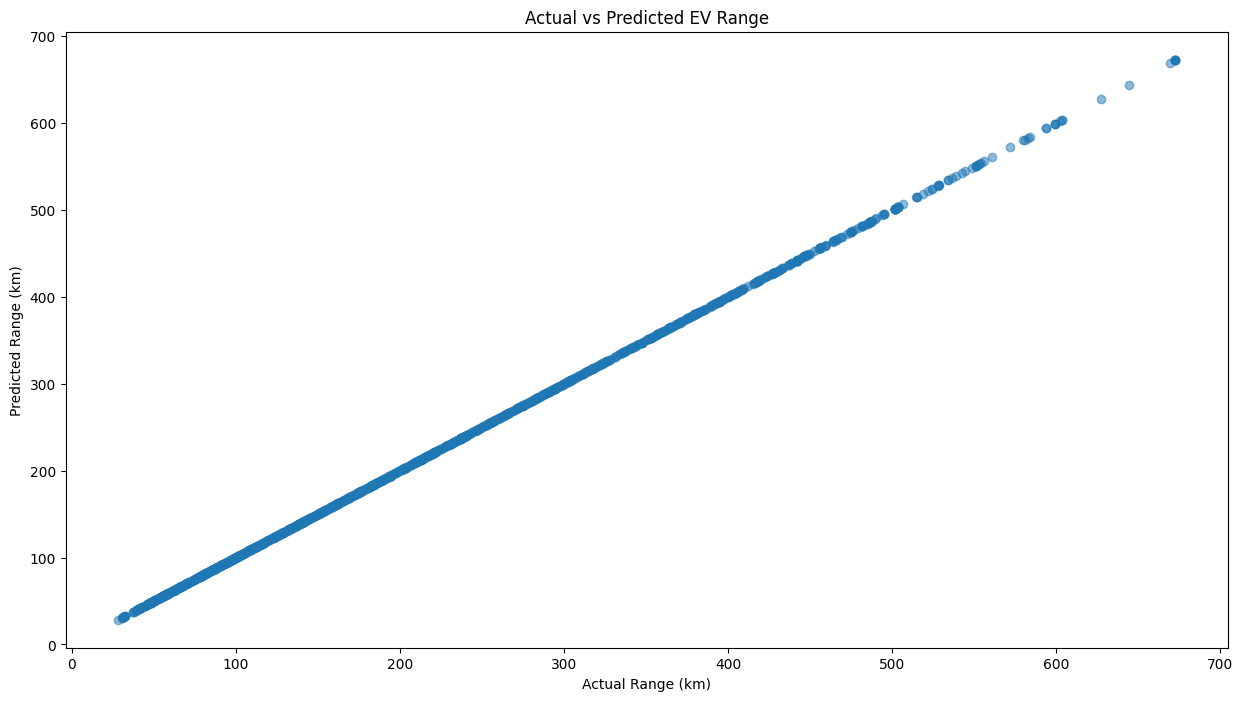

In [200]:
plt.figure(figsize = (15,8))
plt.scatter(y_test, y_pred , alpha = 0.5)
plt.xlabel("Actual Range (km)")
plt.ylabel("Predicted Range (km)")
plt.title("Actual vs Predicted EV Range")
plt.show()

## Error Analysis 

In [202]:
errors = y_test - y_pred

In [203]:
error_df = pd.DataFrame({
    "Actual_Range": y_test,
    "Predicted_Range": y_pred,
    "Error": errors
})

error_df["Absolute_Error"] = error_df["Error"].abs()

error_df.head(10)

,Actual_Range,Predicted_Range,Error,Absolute_Error
1057,83.8,83.784488,0.015512,0.015512
2654,361.9,361.924073,-0.024073,0.024073
4401,474.2,474.291774,-0.091774,0.091774
5843,347.4,347.403575,-0.003575,0.003575
7177,162.3,162.306463,-0.006463,0.006463
3805,438.4,438.498043,-0.098043,0.098043
3961,283.3,283.311317,-0.011317,0.011317
6147,112.7,112.717886,-0.017886,0.017886
3551,426.9,426.867565,0.032435,0.032435
2413,196.9,196.893047,0.006953,0.006953


In [204]:
error_df.sort_values(by='Absolute_Error',ascending = False)


,Actual_Range,Predicted_Range,Error,Absolute_Error
3163,672.6,672.940883,-3.408827e-01,3.408827e-01
3315,644.6,644.323908,2.760918e-01,2.760918e-01
2836,593.8,594.047870,-2.478700e-01,2.478700e-01
960,534.2,533.978650,2.213495e-01,2.213495e-01
3935,484.5,484.282581,2.174194e-01,2.174194e-01
...,...,...,...,...
865,89.5,89.499931,6.911256e-05,6.911256e-05
167,55.3,55.299937,6.251075e-05,6.251075e-05
6245,97.8,97.799944,5.572728e-05,5.572728e-05
1426,102.3,102.300051,-5.092514e-05,5.092514e-05


In [205]:
error_df.head(10)

,Actual_Range,Predicted_Range,Error,Absolute_Error
1057,83.8,83.784488,0.015512,0.015512
2654,361.9,361.924073,-0.024073,0.024073
4401,474.2,474.291774,-0.091774,0.091774
5843,347.4,347.403575,-0.003575,0.003575
7177,162.3,162.306463,-0.006463,0.006463
3805,438.4,438.498043,-0.098043,0.098043
3961,283.3,283.311317,-0.011317,0.011317
6147,112.7,112.717886,-0.017886,0.017886
3551,426.9,426.867565,0.032435,0.032435
2413,196.9,196.893047,0.006953,0.006953


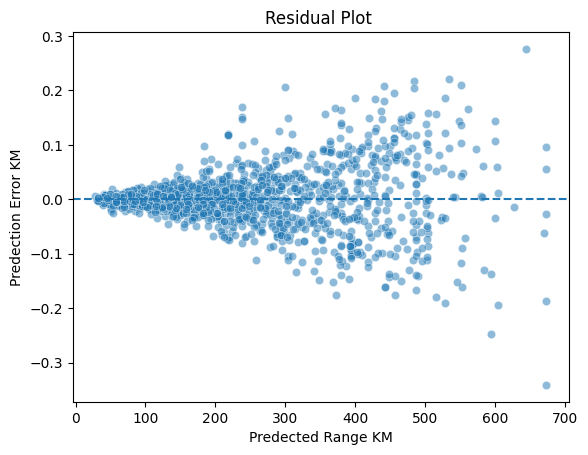

In [206]:
sns.scatterplot(x=y_pred,y = errors , alpha = 0.5)
plt.axhline(y=0,linestyle = '--')
plt.xlabel('Predected Range KM')
plt.ylabel('Predection Error KM')
plt.title('Residual Plot ')
plt.show()

In [207]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² Score:", r2_score(y_test, y_pred))

MAE: 0.03372720616702427
RMSE: 0.053502522767335324
R² Score: 0.999999860426574


In [208]:
print(df[[
    "battery_capacity_kWh",
    "energy_consumption_kWh_per_km",
    "real_world_range_km"
]].head(10))

   battery_capacity_kWh  energy_consumption_kWh_per_km  real_world_range_km
0                  35.3                         0.2504               141.00
1                  40.5                         0.1198               338.00
2                  39.3                         0.1254               313.40
3                  39.0                         0.0883               441.75
4                  37.9                         0.1960               193.40
5                  38.8                         0.1384               280.40
6                  37.9                         0.2658               142.60
7                  38.4                         0.1164               329.80
8                  34.5                         0.1774               194.50
9                  36.6                         0.1426               256.70


In [209]:
print(y_test.describe())
print(pd.Series(y_pred).describe())

count    1459.000000
mean      229.615045
std       143.258954
min        28.500000
25%       106.350000
50%       198.300000
75%       328.150000
max       672.600000
Name: real_world_range_km, dtype: float64
count    1459.000000
mean      229.613575
std       143.256720
min        28.494851
25%       106.339761
50%       198.316196
75%       328.165670
max       672.940883
dtype: float64


In [210]:
df[[
    "battery_capacity_kWh",
    "energy_consumption_kWh_per_km",
    "real_world_range_km"
]].head(10)

,battery_capacity_kWh,energy_consumption_kWh_per_km,real_world_range_km
0,35.3,0.2504,141.00
1,40.5,0.1198,338.00
2,39.3,0.1254,313.40
3,39.0,0.0883,441.75
4,37.9,0.1960,193.40
5,38.8,0.1384,280.40
6,37.9,0.2658,142.60
7,38.4,0.1164,329.80
8,34.5,0.1774,194.50
9,36.6,0.1426,256.70


In [211]:
df[[
    "energy_consumption_kWh_per_km",
    "real_world_range_km"
]].corr()

,energy_consumption_kWh_per_km,real_world_range_km
energy_consumption_kWh_per_km,1.000000,-0.643773
real_world_range_km,-0.643773,1.000000


In [212]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X_check = df_encoded.drop(
    ["real_world_range_km", "energy_consumption_kWh_per_km"],
    axis=1
)
y_check = df_encoded["real_world_range_km"]

X_train_check, X_test_check, y_train_check, y_test_check = train_test_split(
    X_check, y_check, test_size=0.2, random_state=42
)

model_check = LinearRegression()
model_check.fit(X_train_check, y_train_check)

y_pred_check = model_check.predict(X_test_check)

print("MAE:", mean_absolute_error(y_test_check, y_pred_check))
print("RMSE:", np.sqrt(mean_squared_error(y_test_check, y_pred_check)))
print("R²:", r2_score(y_test_check, y_pred_check))

MAE: 0.03366419080087745
RMSE: 0.05347722748914223
R²: 0.9999998605585196


In [213]:
X_check2 = df_encoded.drop(
    ["real_world_range_km",
     "energy_consumption_kWh_per_km",
     "ARAI_certified_range_km"],
    axis=1
)

y_check2 = df_encoded["real_world_range_km"]

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_check2, y_check2, test_size=0.2, random_state=42
)

model_check2 = LinearRegression()
model_check2.fit(X_train2, y_train2)

y_pred2 = model_check2.predict(X_test2)

print("MAE:", mean_absolute_error(y_test2, y_pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test2, y_pred2)))
print("R²:", r2_score(y_test2, y_pred2))

MAE: 0.033664080615593374
RMSE: 0.053475947380374145
R²: 0.9999998605651953


In [214]:
# Check whether the target is present in X_check2
print("Target in features:",
      "real_world_range_km" in X_check2.columns)

# Check highly correlated numerical features
corr = df.select_dtypes(include="number").corr()

print(
    corr["real_world_range_km"]
    .sort_values(ascending=False)
)

Target in features: False
real_world_range_km              1.000000
estimated_range_km               1.000000
ARAI_certified_range_km          0.366001
battery_capacity_kWh             0.325388
battery_capacity_kWh_new         0.321711
motor_efficiency_pct             0.297668
vehicle_weight_kg                0.293342
motor_power_kW                   0.260623
frontal_area_m2                  0.204293
price_lakh_INR                   0.171623
avg_driving_speed_kmh            0.145469
battery_capacity_loose           0.129780
ambient_temperature_C            0.095983
tyre_pressure_deviation_psi      0.003212
passengers                      -0.015710
battery_age_years               -0.048818
driving_style                   -0.087371
ac_usage                        -0.133144
rolling_resistance_Cr           -0.252997
drag_coefficient_Cd             -0.272907
traffic_condition               -0.313941
terrain_type                    -0.632263
energy_consumption_kWh_per_km   -0.643773
Name: re

In [215]:
df[[
    "estimated_range_km",
    "real_world_range_km"
]].head(10)

,estimated_range_km,real_world_range_km
0,140.974441,141.00
1,338.063439,338.00
2,313.397129,313.40
3,441.676104,441.75
4,193.367347,193.40
5,280.346821,280.40
6,142.588412,142.60
7,329.896907,329.80
8,194.475761,194.50
9,256.661992,256.70


In [216]:
df[[
    "estimated_range_km",
    "real_world_range_km"
]].head(10)

,estimated_range_km,real_world_range_km
0,140.974441,141.00
1,338.063439,338.00
2,313.397129,313.40
3,441.676104,441.75
4,193.367347,193.40
5,280.346821,280.40
6,142.588412,142.60
7,329.896907,329.80
8,194.475761,194.50
9,256.661992,256.70


In [217]:
(df["estimated_range_km"] -
 df["real_world_range_km"]).describe()

count    7291.000000
mean        0.000504
std         0.054534
min        -0.322772
25%        -0.015596
50%         0.000000
75%         0.016142
max         0.324901
dtype: float64

In [218]:
X_check3 = df_encoded.drop(
    ["real_world_range_km",
     "estimated_range_km",
     "energy_consumption_kWh_per_km",
     "ARAI_certified_range_km"],
    axis=1,
    errors="ignore"
)

y_check3 = df_encoded["real_world_range_km"]

X_train3, X_test3, y_train3, y_test3 = train_test_split(
    X_check3, y_check3,
    test_size=0.2,
    random_state=42
)

model_check3 = LinearRegression()
model_check3.fit(X_train3, y_train3)

y_pred3 = model_check3.predict(X_test3)

print("MAE:", mean_absolute_error(y_test3, y_pred3))
print("RMSE:", np.sqrt(mean_squared_error(y_test3, y_pred3)))
print("R²:", r2_score(y_test3, y_pred3))

MAE: 44.88428419740889
RMSE: 56.70599608777144
R²: 0.8432122292511173


In [219]:
print("In df:", "estimated_range_km" in df.columns)
print("In df_encoded:", "estimated_range_km" in df_encoded.columns)

print(df[["estimated_range_km", "real_world_range_km"]].head(10))

print(
    (df["estimated_range_km"] - df["real_world_range_km"]).describe()
)

In df: True
In df_encoded: True
   estimated_range_km  real_world_range_km
0          140.974441               141.00
1          338.063439               338.00
2          313.397129               313.40
3          441.676104               441.75
4          193.367347               193.40
5          280.346821               280.40
6          142.588412               142.60
7          329.896907               329.80
8          194.475761               194.50
9          256.661992               256.70
count    7291.000000
mean        0.000504
std         0.054534
min        -0.322772
25%        -0.015596
50%         0.000000
75%         0.016142
max         0.324901
dtype: float64


In [220]:
# Remove features that could leak the target
X = df_encoded.drop(
    columns=[
        "real_world_range_km",
        "estimated_range_km",
        "energy_consumption_kWh_per_km"
    ],
    errors="ignore"
)

y = df_encoded["real_world_range_km"]

# Split the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² Score:", r2_score(y_test, y_pred))

MAE: 44.88128311948296
RMSE: 56.699568810585056
R² Score: 0.8432477691030624


In [221]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Calculate residuals
errors = y_test - y_pred

# Create error analysis table
error_df = pd.DataFrame({
    "Actual_Range": y_test,
    "Predicted_Range": y_pred,
    "Error": errors
})

error_df["Absolute_Error"] = error_df["Error"].abs()

# Display results
print(error_df.head(10))
print("\nMean Error:", errors.mean())
print("Mean Absolute Error:", error_df["Absolute_Error"].mean())

      Actual_Range  Predicted_Range       Error  Absolute_Error
1057          83.8       124.297609  -40.497609       40.497609
2654         361.9       369.401319   -7.501319        7.501319
4401         474.2       422.904915   51.295085       51.295085
5843         347.4       372.341543  -24.941543       24.941543
7177         162.3       155.902192    6.397808        6.397808
3805         438.4       333.458839  104.941161      104.941161
3961         283.3       272.392980   10.907020       10.907020
6147         112.7       181.096142  -68.396142       68.396142
3551         426.9       357.431312   69.468688       69.468688
2413         196.9       196.977662   -0.077662        0.077662

Mean Error: -1.4197255044502048
Mean Absolute Error: 44.88128311948296


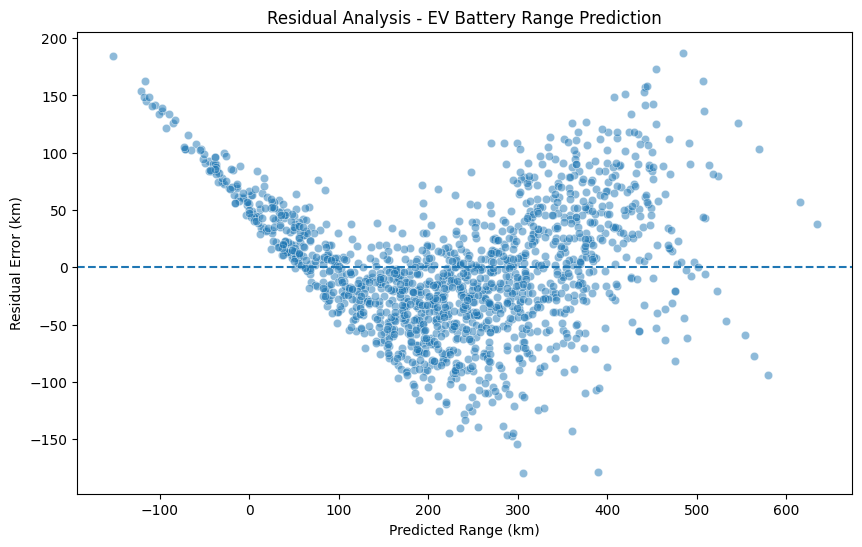

In [222]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x=y_pred, y=errors, alpha=0.5)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Range (km)")
plt.ylabel("Residual Error (km)")
plt.title("Residual Analysis - EV Battery Range Prediction")

plt.show()

In [223]:
print("Minimum predicted range:", y_pred.min())
print("Maximum predicted range:", y_pred.max())

print("Minimum actual range:", y_test.min())
print("Maximum actual range:", y_test.max())

Minimum predicted range: -152.65815889306032
Maximum predicted range: 634.6194855828217
Minimum actual range: 28.5
Maximum actual range: 672.6


In [224]:
import numpy as np

errors = y_test - y_pred

print("Mean Error:", errors.mean())
print("Mean Absolute Error:", np.abs(errors).mean())
print("Largest Absolute Error:", np.abs(errors).max())

print("Negative predictions:", (y_pred < 0).sum())

Mean Error: -1.4197255044502048
Mean Absolute Error: 44.88128311948296
Largest Absolute Error: 187.28759774632056
Negative predictions: 70


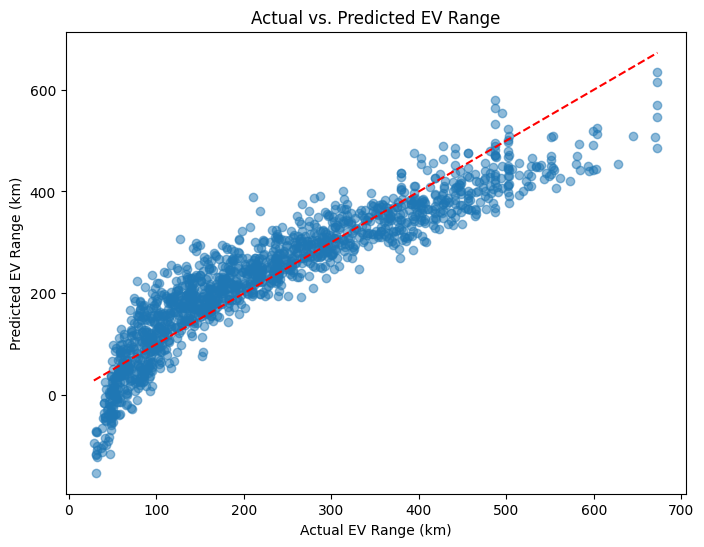

In [225]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual EV Range (km)")
plt.ylabel("Predicted EV Range (km)")
plt.title("Actual vs. Predicted EV Range")
plt.show()

In [226]:
import joblib

joblib.dump(model, "ev_range_linear_regression.pkl")

print("Model saved successfully!")

Model saved successfully!


In [227]:
# Create improved features
X_improved = df_encoded.drop(
    columns=[
        "real_world_range_km",
        "estimated_range_km",
        "energy_consumption_kWh_per_km"
    ],
    errors="ignore"
)

y = df_encoded["real_world_range_km"]

print("Features shape:", X_improved.shape)
print("Target shape:", y.shape)
print("Target included in features:", "real_world_range_km" in X_improved.columns)

Features shape: (7291, 130)
Target shape: (7291,)
Target included in features: False


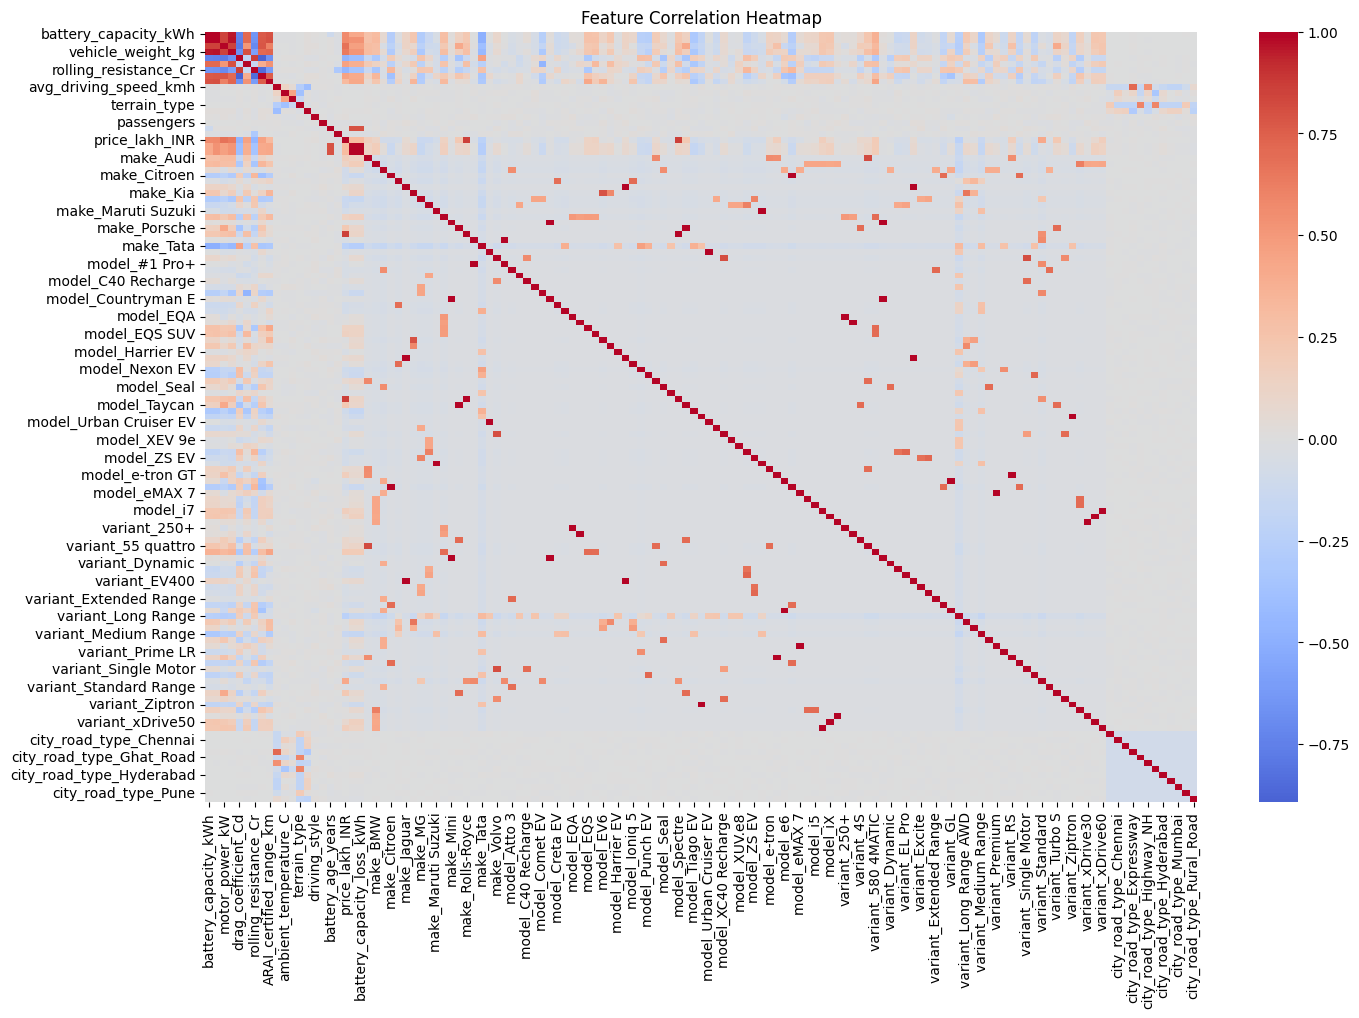

Improved Model Results
----------------------
MAE: 44.71538761192586
RMSE: 56.525264302933074
R² Score: 0.8442100558970229
Negative predictions: 70


In [228]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Create useful features
df_improved = df.copy()

# Battery capacity loss
df_improved["battery_capacity_loss_kWh"] = (
    df_improved["battery_capacity_kWh_new"]
    - df_improved["battery_capacity_kWh"]
)

# Remove target leakage and original target-related columns
df_improved = df_improved.drop(
    columns=[
        "estimated_range_km",
        "energy_consumption_kWh_per_km"
    ],
    errors="ignore"
)

# 2. Encode categorical features
df_improved = pd.get_dummies(
    df_improved,
    columns=["make", "model", "variant", "city_road_type"],
    dtype=int
)

# Separate features and target
X = df_improved.drop(columns=["real_world_range_km"])
y = df_improved["real_world_range_km"]

# 3. Check multicollinearity using correlation
corr = X.select_dtypes(include="number").corr()

plt.figure(figsize=(16, 10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()

# 4. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Standardize numerical features
numeric_cols = X_train.select_dtypes(include="number").columns

scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()

X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

# 6. Train Linear Regression
model_improved = LinearRegression()
model_improved.fit(X_train, y_train)

# 7. Make predictions
y_pred_improved = model_improved.predict(X_test)

# 8. Evaluate the improved model
print("Improved Model Results")
print("----------------------")
print("MAE:", mean_absolute_error(y_test, y_pred_improved))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_improved)))
print("R² Score:", r2_score(y_test, y_pred_improved))

# 9. Check negative predictions
print("Negative predictions:", (y_pred_improved < 0).sum())


In [229]:
corr = X.corr(numeric_only=True)

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .loc[lambda s: s.abs() > 0.90]
    .sort_values(key=abs, ascending=False)
)

print(high_corr)

make_Smart                model_#1 Pro+                1.000000
make_Toyota               model_Urban Cruiser EV       1.000000
model_iX                  variant_xDrive50             1.000000
model_i7                  variant_xDrive60             1.000000
model_eMAX 7              variant_Premium              1.000000
model_e6                  variant_GL                   1.000000
model_e-tron GT           variant_RS                   1.000000
model_Tigor EV            variant_Ziptron              1.000000
model_I-PACE              variant_EV400                1.000000
model_EQB                 variant_350 4MATIC           1.000000
model_EQA                 variant_250+                 1.000000
model_Countryman E        variant_ALL4                 1.000000
model_iX1                 variant_xDrive30             1.000000
make_Rolls-Royce          model_Spectre                1.000000
make_Porsche              model_Taycan                 1.000000
make_Mini                 variant_ALL4  

In [230]:
# Remove one duplicate battery-loss feature
X_final = X.drop(
    columns=["battery_capacity_loose"],
    errors="ignore"
)

print("Original features:", X.shape[1])
print("Features after removing duplicate:", X_final.shape[1])
print("Duplicate feature removed successfully!")

Original features: 131
Features after removing duplicate: 130
Duplicate feature removed successfully!


In [231]:
# Split the updated features
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final, y, test_size=0.2, random_state=42
)

# Standardize numerical features
numeric_cols = X_train_final.select_dtypes(include="number").columns

scaler_final = StandardScaler()

X_train_final = X_train_final.copy()
X_test_final = X_test_final.copy()

X_train_final[numeric_cols] = scaler_final.fit_transform(
    X_train_final[numeric_cols]
)

X_test_final[numeric_cols] = scaler_final.transform(
    X_test_final[numeric_cols]
)

# Train Linear Regression
model_final = LinearRegression()
model_final.fit(X_train_final, y_train_final)

# Predict
y_pred_final = model_final.predict(X_test_final)

# Evaluate
print("MAE:", mean_absolute_error(y_test_final, y_pred_final))
print("RMSE:", np.sqrt(mean_squared_error(y_test_final, y_pred_final)))
print("R² Score:", r2_score(y_test_final, y_pred_final))

MAE: 44.71538761192549
RMSE: 56.5252643029328
R² Score: 0.8442100558970245


In [232]:

# 1. Import libraries
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Split data
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final, y, test_size=0.2, random_state=42
)

# 3. Scale numerical features
numeric_cols = X_train_final.select_dtypes(include="number").columns

scaler_final = StandardScaler()

X_train_final = X_train_final.copy()
X_test_final = X_test_final.copy()

X_train_final[numeric_cols] = scaler_final.fit_transform(
    X_train_final[numeric_cols]
)
X_test_final[numeric_cols] = scaler_final.transform(
    X_test_final[numeric_cols]
)

# 4. Train final Linear Regression model
final_model = LinearRegression()
final_model.fit(X_train_final, y_train_final)

# 5. Predict
y_pred_final = final_model.predict(X_test_final)

# 6. Evaluate
print("FINAL LINEAR REGRESSION MODEL")
print("-----------------------------")
print("MAE:", mean_absolute_error(y_test_final, y_pred_final))
print("RMSE:", np.sqrt(mean_squared_error(y_test_final, y_pred_final)))
print("R² Score:", r2_score(y_test_final, y_pred_final))

# 7. Save model and scaler
joblib.dump(final_model, "final_ev_range_model.pkl")
joblib.dump(scaler_final, "final_ev_range_scaler.pkl")

print("\nFinal model and scaler saved successfully!")


FINAL LINEAR REGRESSION MODEL
-----------------------------
MAE: 44.71538761192549
RMSE: 56.5252643029328
R² Score: 0.8442100558970245

Final model and scaler saved successfully!


In [233]:
import joblib

# Save the exact feature columns used by the final model
joblib.dump(X_final.columns.tolist(), "ev_feature_columns.pkl")

# Save the complete preprocessing objects
joblib.dump(scaler_final, "final_ev_range_scaler.pkl")
joblib.dump(final_model, "final_ev_range_model.pkl")

print("Model, scaler, and feature columns saved successfully!")

Model, scaler, and feature columns saved successfully!


In [234]:
# Select one sample from the test data
sample_ev = X_test_final.iloc[[0]]

# Predict its range
predicted_range = final_model.predict(sample_ev)[0]

print("Predicted EV Range:", round(predicted_range, 2), "km")
print("Actual EV Range:", round(y_test_final.iloc[0], 2), "km")

Predicted EV Range: 112.76 km
Actual EV Range: 83.8 km
